# Quantum GAN -- a generative model built from a statevector

**Project 10 of the portfolio. Level: Advanced. Libraries: PennyLane (cross-check only) / PyTorch-style classical baseline.**

We build a Generative Adversarial Network whose **generator is a parameterised quantum circuit**
and whose **discriminator is a classical network**, entirely in NumPy: gate matrices, the ansatz,
the parameter-shift gradients, the critic's back-propagation, Adam, total-variation and
2-Wasserstein distances. Nothing is hidden behind a framework until the final cross-check cell.

| Part | What we do |
|---|---|
| 1 | Target distributions over $2^n$ bitstrings + the three metrics we track |
| 2 | The quantum generator from scratch: gates, ring-CNOT ansatz, exact probabilities, parameter shift |
| 3 | Classical discriminator (NumPy MLP with hand-derived back-prop), Adam, the classical generator baseline |
| 4 | Train quantum vs classical under the *same* objective and optimizer |
| 5 | Training stability, measured: divergence, recovery, mode coverage |
| 6 | The alternative critic: a Hermitian $2^d\times 2^d$ observable, and phase blindness |
| 7 | Depth / parameter sweep, the consolidated measurement table, and an honesty note |
| 8 | 150+ self-tests |
| 9 | PennyLane cross-check, final report, recap and exercises |

**Note on PyTorch:** `torch` is not available in this notebook's runtime, so the classical
discriminator and its gradient descent are written in pure NumPy. The arithmetic is identical --
PyTorch would only have automated the bookkeeping of the chain rule we do by hand below.

## Part 1 -- Targets and metrics

A $d = 2^n$ outcome quantum generator is a point on a $(d-1)$-simplex *induced* from a sphere of
amplitudes, so we need target distributions on exactly that simplex. We use three, of increasing
hardness for a small circuit:

1. **`gauss`** -- a 1-D Gaussian binned over the $2^n$ basis states (smooth, unimodal).
2. **`multi`** -- several Gaussians on a ring of bins, i.e. the 8-Gaussians-on-a-ring style target
   with as many bumps as the register can actually resolve ($d/4$: four bumps at $n=4$, eight at
   $n=5$). This is the classic mode-collapse test; with 8 bumps crammed into 16 bins the "modes"
   overlap and the target is numerically indistinguishable from uniform, which would make the
   collapse experiment meaningless -- we measured that and fixed the geometry instead.
3. **`delta`** -- a single random bitstring with all the mass (sharpest test; also the one the circuit can prepare exactly).

Metrics, all implemented from scratch: **total variation** (sup over events, $\tfrac12\sum|p-q|$),
**1-D 2-Wasserstein** via the optimal monotone/quantile coupling (an interval scan, not the
$\int|F-G|^2$ shortcut -- that identity is only true for $W_1$, a trap worth knowing), and
**mode coverage** = fraction of *significant* target bumps (those carrying at least $1/(2m)$ of the
mass) that captured at least 25% of their target mass.

In [1]:
# Part 1 code: imports, deterministic RNG, sigmoid/softmax, and the three metrics.
import time
import numpy as np
import matplotlib.pyplot as plt

T_START = time.perf_counter()
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.30,
                     "legend.fontsize": 8, "axes.titlesize": 9})

SEED = 20261101
LOG_FLOOR = 1e-12          # floor inside log() so log(0) never appears
rng_master = np.random.default_rng(SEED)

def sigmoid(z):
    z = np.asarray(z, dtype=float)
    return 0.5 * (1.0 + np.tanh(0.5 * z))

def softmax(v, axis=-1):
    v = np.asarray(v, dtype=float)
    v = v - np.max(v, axis=axis, keepdims=True)
    e = np.exp(v)
    return e / np.sum(e, axis=axis, keepdims=True)

def total_variation(p, q):
    return 0.5 * float(np.sum(np.abs(np.asarray(p, float) - np.asarray(q, float))))

def w2_1d(p, q, x):
    # Exact 1-D quadratic optimal transport = cost of the monotone (quantile) coupling.
    p = np.asarray(p, float) / np.sum(p)
    q = np.asarray(q, float) / np.sum(q)
    cp = np.cumsum(p); cq = np.cumsum(q)
    i = j = 0; a = 0.0; acc = 0.0
    N = len(p)
    while i < N and j < N:
        b = min(cp[i], cq[j])
        if b > a:
            acc += (b - a) * (x[i] - x[j]) ** 2
            a = b
        if cp[i] == b:
            i += 1
        if cq[j] == b:
            j += 1
    return float(np.sqrt(max(acc, 0.0)))

def bump_masses(p, slices):
    return np.array([float(np.sum(p[s])) for s in slices], dtype=float)

def significant(need, n_bumps):
    # A bump is a "mode" only if the target actually puts mass there: keeps a 15-bin tail of a
    # one-hot target from being counted as 15 missed modes.
    thr = 0.5 / max(n_bumps, 1)
    return np.array([i for i in range(len(need)) if need[i] >= thr], dtype=int)

def mode_coverage(p, t, slices, frac_needed=0.25):
    need = bump_masses(t, slices)
    got = bump_masses(p, slices)
    ratio = np.zeros_like(need)
    for m in range(len(need)):
        if need[m] > 1e-12:
            ratio[m] = got[m] / need[m]
    keep = significant(need, len(slices))
    if len(keep) == 0:
        return 1.0, ratio
    return float(np.mean(ratio[keep] >= frac_needed)), ratio

### Why the Wasserstein scan looks the way it does

For 1-D distributions the optimal coupling for a convex cost matches quantiles to quantiles. Walking
the cumulative sums, the interval where the $i$-th target bin and the $j$-th generated bin are
simultaneously "active" contributes `(length of interval) * (x_i - x_j)^2`. That is the exact value
of $\int_0^1 (Q_p - Q_q)^2 du$, and it also lets us test the function on cases we can do by hand:
$\delta_a$ vs $\delta_b$ must equal $|x_a-x_b|$ exactly, and moving one bin of a grid-Gaussian by $k$
bins must increase $W_2$ predictably. Those tests appear in the self-test suite.

target normalisations: ['1.0000000000000000', '1.0000000000000000', '1.0000000000000000']
gauss max/sum: 0.237823 1.000000
multi bump heights: [0.25 0.25 0.25 0.25]
TV of each target against the uniform distribution: gauss 0.5582, multi 0.2194, delta 0.9375
multi has 4 resolved bumps at n=4


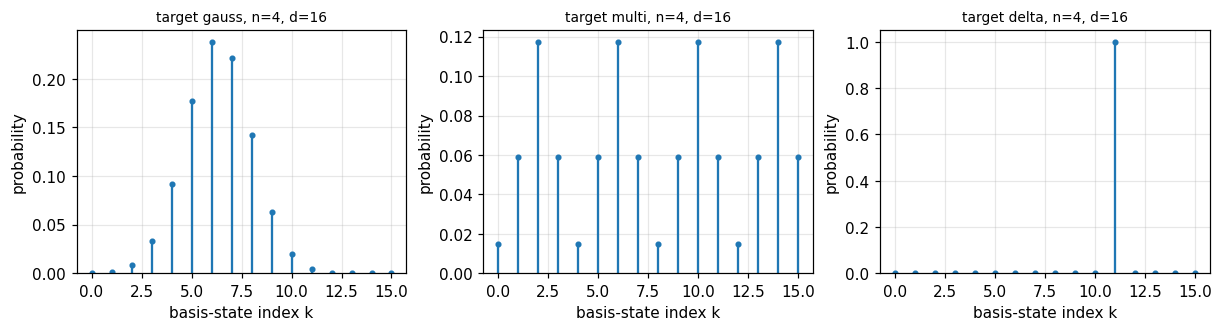

In [2]:
# Part 1 code: the three target distributions + Figure 1.
def bin_positions(d):
    return np.arange(d, dtype=float)

def make_gauss(n, mu_frac=0.42, sig_frac=0.11):
    d = 2 ** n
    x = np.arange(d, dtype=float)
    mu = mu_frac * (d - 1)
    s = max(sig_frac * (d - 1), 0.8)
    p = np.exp(-0.5 * ((x - mu) / s) ** 2)
    p = p / p.sum()
    slices = [slice(a, a + d // 4) for a in range(0, d, d // 4)]
    return p, {"x": bin_positions(d), "slices": slices, "name": "gauss"}

def make_multi(n, width=0.85, n_bumps=None):
    d = 2 ** n
    x = np.arange(d, dtype=float)
    if n_bumps is None:
        n_bumps = max(2, d // 4)          # only this many bumps fit without overlapping
    p = np.zeros(d)
    for m in range(n_bumps):
        c = (m + 0.5) * d / n_bumps    # centres mid-arc, so every peak is an interior local max
        for shift in (-d, 0.0, d):          # ring = periodic images
            p += np.exp(-0.5 * ((x - (c + shift)) / width) ** 2)
    p = p / p.sum()
    arc = d // n_bumps
    slices = [slice(m * arc, (m + 1) * arc) for m in range(n_bumps)]
    return p, {"x": bin_positions(d), "slices": slices, "name": "multi", "n_bumps": n_bumps}

def make_delta(n, key=11):
    d = 2 ** n
    k = key % d
    p = np.full(d, 1e-6 / (d - 1))
    p[k] = 1.0 - 1e-6
    slices = [slice(k, k + 1)]
    return p, {"x": bin_positions(d), "slices": slices, "name": "delta", "k": k}

N_MAIN = 4
TARGETS = {"gauss": make_gauss(N_MAIN), "multi": make_multi(N_MAIN),
           "delta": make_delta(N_MAIN, key=11)}

fig, axes = plt.subplots(1, 3, figsize=(11.0, 2.9), constrained_layout=True)
for ax, key in zip(axes, ("gauss", "multi", "delta")):
    p, meta = TARGETS[key]
    ax.stem(meta["x"], p, markerfmt=".", basefmt=" ")
    ax.set_title("target %s, n=%d, d=%d" % (key, N_MAIN, len(p)))
    ax.set_xlabel("basis-state index k")
    ax.set_ylabel("probability")
    ax.set_ylim(0, 1.05 * p.max())
print("target normalisations:", ["%.16f" % TARGETS[k][0].sum() for k in TARGETS])
print("gauss max/sum:", "%.6f" % TARGETS["gauss"][0].max(), "%.6f" % TARGETS["gauss"][0].sum())
print("multi bump heights:", np.round(bump_masses(TARGETS["multi"][0], TARGETS["multi"][1]["slices"]), 4))
_u16 = np.full(2 ** N_MAIN, 1.0 / (2 ** N_MAIN))
print("TV of each target against the uniform distribution:",
      ", ".join("%s %.4f" % (k, total_variation(TARGETS[k][0], _u16)) for k in TARGETS))
print("multi has %d resolved bumps at n=%d" % (len(TARGETS["multi"][1]["slices"]), N_MAIN))
plt.show()

## Part 2 -- The quantum generator, from scratch

A pure state on $n$ qubits is a unit vector in $\mathbb{C}^{2^n}$; we store it as a flat complex
array of length $d = 2^n$ and index it with the big-endian convention (qubit 0 is the most
significant bit, matching `np.kron` order and PennyLane's wire order). A gate on one or two
qubits is applied by reshaping the statevector to $(2,)^n$, moving the acted-on axes to the front,
contracting with the gate matrix, and moving back.

The ansatz is deliberately simple and fully transparent:

$$U(\theta)=\prod_{l=1}^{L}\Big[\big(\textstyle\prod_j \mathrm{Ry}(\theta_{(l+1),j})\big)\ \mathrm{CNOTring}\Big]\ \prod_j \mathrm{Ry}(\theta_{0,j})$$

* one layer of single-qubit $\mathrm{Ry}$ rotations,
* then $L$ repetitions of "ring of CNOTs ($j \to j{+}1 \bmod n$)" followed by another $\mathrm{Ry}$ layer,
* $n(L+1)$ trainable parameters, all real.

Because every gate here is real, the statevector stays real: this generator produces
distributions on the simplex via $p_k = |\psi_k|^2$ **without using phases**. That limitation is
real and we measure its consequence in Part 6.

In [3]:
# Part 2 code: gate matrices, and statevector gate application by axis contraction.
I2 = np.eye(2, dtype=complex)
SX = np.array([[0, 1], [1, 0]], dtype=complex)
SZ = np.array([[1, 0], [0, -1]], dtype=complex)
HAD = np.array([[1, 1], [1, -1]], dtype=complex) / np.sqrt(2.0)
CX4 = np.array([[1, 0, 0, 0],
                [0, 1, 0, 0],
                [0, 0, 0, 1],
                [0, 0, 1, 0]], dtype=complex)   # control = more significant of the two axes

def ry(t):
    return np.array([[np.cos(t / 2.0), -np.sin(t / 2.0)],
                     [np.sin(t / 2.0),  np.cos(t / 2.0)]], dtype=complex)

def rz(t):
    return np.array([[np.exp(-0.5j * t), 0.0],
                     [0.0, np.exp(0.5j * t)]], dtype=complex)

def apply_1q(psi, op, q, n):
    t = np.moveaxis(psi.reshape([2] * n), q, 0)
    sh = t.shape
    r = np.tensordot(np.asarray(op, complex), t.reshape(2, -1), axes=(1, 0))
    return np.moveaxis(r.reshape([2] + list(sh[1:])), 0, q).reshape(-1)

def apply_2q(psi, op4, c, tg, n):
    t = np.moveaxis(psi.reshape([2] * n), [c, tg], [0, 1])
    sh = t.shape
    r = np.tensordot(np.asarray(op4, complex), t.reshape(4, -1), axes=(1, 0))
    r = r.reshape([2, 2] + list(sh[2:]))
    return np.moveaxis(r, [0, 1], [c, tg]).reshape(-1)

def kron_all(mats):
    out = np.array([[1.0 + 0.0j]])
    for m in mats:
        out = np.kron(out, m)
    return out

def gate_full(op, q, n):
    return kron_all([op if k == q else I2 for k in range(n)])

def cnot_full(c, tg, n):
    d = 2 ** n
    M = np.zeros((d, d), dtype=complex)
    for i in range(d):
        cb = (i >> (n - 1 - c)) & 1
        j = i ^ (cb << (n - 1 - tg))
        M[j, i] += 1.0
    return M

def bitstring(k, n):
    return "".join(str((k >> (n - 1 - b)) & 1) for b in range(n))

# quick internal sanity print (also asserted later in the suite)
_psi = np.zeros(16, complex); _psi[0] = 1.0
_psi = apply_1q(_psi, ry(np.pi), 0, 4)
print("Ry(pi) on qubit 0 of |0000> -> bitstring index", int(np.argmax(np.abs(_psi) ** 2)),
      "=", bitstring(int(np.argmax(np.abs(_psi) ** 2)), 4))
_c01 = np.array([apply_2q(np.eye(16, dtype=complex)[:, k].copy(), CX4, 0, 1, 4) for k in range(16)]).T
print("cnot_full(0,1) agrees with apply_2q:", bool(np.allclose(cnot_full(0, 1, 4), _c01)))

Ry(pi) on qubit 0 of |0000> -> bitstring index 8 = 1000
cnot_full(0,1) agrees with apply_2q: True


### Two independent routes to the same probabilities

Route A applies gates to the statevector (cheap: $O(n\,d^2)$). Route B multiplies the gate
*matrices* together into a dense unitary and then applies it (costly but gives the unitary we can
verify: $U U^\dagger = \mathbb{1}$). We assert their agreement, and we assert the generator
distribution equals $|(U e_0)_k|^2$ for that independently built $U$ -- that is the check that
catches a wrong kron order or a flipped control/target bit.

Gradients come from the **parameter-shift rule**. Every trainable gate is a $\mathrm{Ry}$, whose
generator has eigenvalues $\pm\tfrac12$, so for *any* function of the circuit that is an
expectation value of an observable -- including a single probability $p_k = \langle\psi|\,|k\rangle\langle k|\,|\psi\rangle$:

$$\frac{\partial p_k}{\partial\theta_i}=\tfrac12\Big[p_k(\theta+\tfrac{\pi}{2}\hat e_i)-p_k(\theta-\tfrac{\pi}{2}\hat e_i)\Big]$$

exact, no step-size choice. We still compare it with a central difference below, because "exact"
is a claim you should verify, not a claim you should trust.

In [4]:
# Part 2 code: the ansatz, dense-unitary route, parameter-shift gradient.
def n_params(n, L):
    return n * (L + 1)

def gen_state(theta, n, L):
    psi = np.zeros(2 ** n, dtype=complex)
    psi[0] = 1.0
    for j in range(n):
        psi = apply_1q(psi, ry(theta[j]), j, n)
    for l in range(L):
        for j in range(n):
            psi = apply_2q(psi, CX4, j, (j + 1) % n, n)
        off = (l + 1) * n
        for j in range(n):
            psi = apply_1q(psi, ry(theta[off + j]), j, n)
    return psi

def gen_probs(theta, n, L):
    psi = gen_state(theta, n, L)
    return np.abs(psi) ** 2

def dense_unitary(theta, n, L):
    d = 2 ** n
    gates = []
    for j in range(n):
        gates.append(gate_full(ry(theta[j]), j, n))
    for l in range(L):
        for j in range(n):
            gates.append(cnot_full(j, (j + 1) % n, n))
        off = (l + 1) * n
        for j in range(n):
            gates.append(gate_full(ry(theta[off + j]), j, n))
    U = np.eye(d, dtype=complex)
    for G in gates:
        U = G @ U
    return U

def grad_probs_shift(theta, n, L):
    # Batched parameter shift: all 2P shifted circuits are evaluated as one array operation.
    P = len(theta)
    TH = np.tile(np.asarray(theta, dtype=float), (2 * P, 1))
    ar = np.arange(P)
    TH[ar, ar] += 0.5 * np.pi
    TH[P + ar, ar] -= 0.5 * np.pi
    PP = gen_probs_batch(TH, n, L)
    return 0.5 * (PP[:P] - PP[P:])

def grad_probs_shift_loop(theta, n, L):
    # The same rule written the obvious way; kept so the batched version can be audited.
    rows = []
    for i in range(len(theta)):
        tp = np.array(theta, copy=True); tp[i] += 0.5 * np.pi
        tm = np.array(theta, copy=True); tm[i] -= 0.5 * np.pi
        rows.append(0.5 * (gen_probs(tp, n, L) - gen_probs(tm, n, L)))
    return np.stack(rows, axis=0)

def apply_1q_batch(psi, ops, q, n):
    B = psi.shape[0]
    t = np.moveaxis(psi.reshape(B, *([2] * n)), q + 1, 1)
    sh = t.shape
    r = np.einsum("bij,bjk->bik", np.asarray(ops, complex), t.reshape(B, 2, -1))
    r = r.reshape(B, 2, *sh[2:])
    return np.moveaxis(r, 1, q + 1).reshape(B, -1)

def apply_2q_batch(psi, op4, c, tg, n):
    B = psi.shape[0]
    t = np.moveaxis(psi.reshape(B, *([2] * n)), [c + 1, tg + 1], [1, 2])
    sh = t.shape
    r = np.einsum("ij,bjk->bik", np.asarray(op4, complex), t.reshape(B, 4, -1))
    r = r.reshape(B, 2, 2, *sh[3:])
    return np.moveaxis(r, [1, 2], [c + 1, tg + 1]).reshape(B, -1)

def _ry_ops(ang):
    ang = np.asarray(ang, float)
    c = np.cos(ang / 2.0); s = np.sin(ang / 2.0)
    O = np.zeros((len(ang), 2, 2), dtype=complex)
    O[:, 0, 0] = c; O[:, 0, 1] = -s
    O[:, 1, 0] = s; O[:, 1, 1] = c
    return O

def gen_state_batch(TH, n, L):
    d = 2 ** n
    B = TH.shape[0]
    psi = np.zeros((B, d), dtype=complex)
    psi[:, 0] = 1.0
    for j in range(n):
        psi = apply_1q_batch(psi, _ry_ops(TH[:, j]), j, n)
    for l in range(L):
        for j in range(n):
            psi = apply_2q_batch(psi, CX4, j, (j + 1) % n, n)
        off = (l + 1) * n
        for j in range(n):
            psi = apply_1q_batch(psi, _ry_ops(TH[:, off + j]), j, n)
    return psi

def gen_probs_batch(TH, n, L):
    return np.abs(gen_state_batch(TH, n, L)) ** 2

def grad_probs_fd(theta, n, L, h=1e-5):
    rows = []
    for i in range(len(theta)):
        tp = np.array(theta, copy=True); tp[i] += h
        tm = np.array(theta, copy=True); tm[i] -= h
        rows.append((gen_probs(tp, n, L) - gen_probs(tm, n, L)) / (2.0 * h))
    return np.stack(rows, axis=0)

th0 = 0.4 * rng_master.standard_normal(n_params(N_MAIN, 2))
U0 = dense_unitary(th0, N_MAIN, 2)
p_state = gen_probs(th0, N_MAIN, 2)
p_dense = np.abs(U0 @ np.eye(16, dtype=complex)[:, 0]) ** 2
_unit_err = float(np.max(np.abs(U0 @ U0.conj().T - np.eye(16))))
_shift_fd = float(np.max(np.abs(grad_probs_shift(th0, N_MAIN, 2)
                                - grad_probs_fd(th0, N_MAIN, 2))))
print("unitarity error max|UU+ - I| : %.3e" % _unit_err)
print("statevector vs dense unitary probs: %.3e" % float(np.max(np.abs(p_state - p_dense))))
print("sum probs - 1: %.3e ; min prob: %.3e" % (p_state.sum() - 1.0, p_state.min()))
print("parameter-shift vs central-difference gradient: %.3e (max abs)" % _shift_fd)
_batch_loop = float(np.max(np.abs(grad_probs_shift(th0, N_MAIN, 2)
                                  - grad_probs_shift_loop(th0, N_MAIN, 2))))
print("batched vs one-circuit-at-a-time parameter shift: %.3e (max abs)" % _batch_loop)
print("row sums of shift gradient (must be 0): max %.3e" % np.max(np.abs(grad_probs_shift(th0, N_MAIN, 2).sum(axis=1))))
_sv = -np.sum(p_state * np.log(p_state + 1e-300))
print("Shannon entropy of generated dist = %.4f nats (log 16 = %.4f)" % (_sv, np.log(16)))

# A ring of CNOTs maps computational basis states to basis states (it is a linear map over GF(2)),
# so preparing a single bitstring exactly needs a *pre-image* under that permutation, not the bits
# themselves. We find the pre-image by brute force and use it later as a hard self-test.
def cnot_ring_index_map(n, L):
    fwd = {}
    for b in range(2 ** n):
        v = np.zeros(2 ** n, dtype=complex)
        v[b] = 1.0
        for l in range(L):
            for j in range(n):
                v = apply_2q(v, CX4, j, (j + 1) % n, n)
        fwd[int(np.argmax(np.abs(v)))] = b
    return fwd

def prep_theta_for(k, n, L):
    img = cnot_ring_index_map(n, L)
    b = img[k]
    th = np.zeros(n_params(n, L))
    for j in range(n):
        if (b >> (n - 1 - j)) & 1:
            th[j] = np.pi
    return th, b

_th_pre, _b_pre = prep_theta_for(TARGETS["delta"][1]["k"], N_MAIN, 2)
print("exact prep of bitstring %s: pre-image bits %s, TV = %.3e, min prob = %.3e"
      % (bitstring(TARGETS["delta"][1]["k"], N_MAIN), bitstring(_b_pre, N_MAIN),
         total_variation(gen_probs(_th_pre, N_MAIN, 2), TARGETS["delta"][0]),
         gen_probs(_th_pre, N_MAIN, 2).min()))

unitarity error max|UU+ - I| : 1.332e-15
statevector vs dense unitary probs: 0.000e+00
sum probs - 1: -6.661e-16 ; min prob: 3.095e-06
parameter-shift vs central-difference gradient: 2.695e-11 (max abs)
batched vs one-circuit-at-a-time parameter shift: 8.327e-17 (max abs)
row sums of shift gradient (must be 0): max 1.943e-16
Shannon entropy of generated dist = 1.1520 nats (log 16 = 2.7726)
exact prep of bitstring 1011: pre-image bits 0011, TV = 1.000e-06, min prob = 0.000e+00


## Part 3 -- The critics, Adam, and the classical generator baseline

The adversarial objective is fixed once and used for **every** run in this notebook, quantum and
classical alike, so the comparison is fair. We use the standard non-saturating GAN pair with binary
cross-entropy over the $d$ outcomes, and -- importantly -- we replace mini-batch sampling by the
**exact expectation over all $2^n$ outcomes**:

$$L_D=-\sum_k t_k\log\sigma(z_k)-\sum_k p_\theta(k)\log\big(1-\sigma(z_k)\big),\qquad
L_G=-\sum_k p_\theta(k)\log\sigma(z_k)$$

where $z_k$ is the discriminator logit for bitstring $k$. With this choice the only source of
instability left is the adversarial drift itself, not Monte-Carlo noise: when our curves diverge we
can say exactly why.

The classical critic is a two-layer MLP (one-hot bitstring $\to$ 16 relu units $\to$ logit) written
in NumPy, with its back-propagation derived by hand and then verified against a central difference.

In [5]:
# Part 3 code: classical MLP discriminator in NumPy + analytic gradients.
class MLPDisc:
    def __init__(self, d, hidden=16, rng=None):
        rng = np.random.default_rng(12345) if rng is None else rng
        self.d = d
        self.hidden = hidden
        self.X = np.eye(d)                                  # one-hot bitstring features
        self.p = [rng.standard_normal((hidden, d)) / np.sqrt(d),
                  np.zeros(hidden),
                  rng.standard_normal(hidden) / np.sqrt(hidden),
                  np.zeros(())]
        self._cache = None
    # ---- forward
    def z_logits(self):
        W1, b1, W2, b2 = self.p
        z1 = W1 @ self.X + b1[:, None]
        a1 = np.maximum(z1, 0.0)
        z = W2 @ a1 + float(b2)
        self._cache = (z1, a1)
        return z
    def scores(self):
        return sigmoid(self.z_logits())
    # ---- weighted BCE gradient, weights = (real distribution, fake distribution)
    def loss_and_grad(self, t, pfake):
        W1, b1, W2, b2 = self.p
        z = self.z_logits()
        s = sigmoid(z)
        loss = -float(np.sum(t * np.log(s + LOG_FLOOR))) \
               - float(np.sum(pfake * np.log(1.0 - s + LOG_FLOOR)))
        gz = -t * (1.0 - s) + pfake * s            # dL/dz  (dlog sig/dz = 1-sig, dlog(1-sig)/dz = -sig)
        z1, a1 = self._cache
        gb2 = np.array(np.sum(gz))
        gW2 = a1 @ gz
        ga1 = W2[:, None] * gz[None, :]
        gz1 = ga1 * (z1 > 0.0)
        gW1 = gz1 @ self.X.T
        gb1 = gz1.sum(axis=1)
        return loss, [gW1, gb1, gW2, gb2]

def _flatten(params):
    return np.concatenate([np.asarray(p, dtype=float).reshape(-1) for p in params])

def _unflatten(params, flat, idx, delta):
    new, off = [], 0
    for p in params:
        arr = np.asarray(p, dtype=float)
        sz = arr.size
        q = arr.reshape(-1).copy()
        if off <= idx < off + sz:
            q[idx - off] += delta
        new.append(q.reshape(arr.shape))
        off += sz
    return new

def central_diff_grad(fn, params, h=1e-5):
    # fn(params_list) -> scalar; returns gradient lists with the same shapes as params
    flat = _flatten(params)
    g = np.zeros_like(flat)
    for idx in range(len(flat)):
        gp = (fn(_unflatten(params, flat, idx, +h)) - fn(_unflatten(params, flat, idx, -h))) / (2.0 * h)
        g[idx] = gp
    out, off = [], 0
    for p in params:
        arr = np.asarray(p, dtype=float)
        out.append(g[off:off + arr.size].reshape(arr.shape))
        off += arr.size
    return out

### Adam in ten lines, and why it belongs in a teaching notebook

Adam keeps an exponential moving average of the gradient ($m$) and of its square ($v$), and
*debiasises both* because at step 1 the raw averages are pulled toward zero. The update direction
is $m/\sqrt{v}$, so a parameter whose gradients are consistently small still moves at a rate set by
`lr`, while a parameter with sporadic huge gradients is tamed. That normalisation is precisely why
`lr` becomes an interpretable step size in units of "parameters" -- and why a too-large `lr` in a
GAN is a genuine collapse mechanism rather than a mere overshoot. We will assert that the very first
Adam step for a unit gradient has magnitude exactly `lr`.

In [6]:
# Part 3 code: Adam, gradient clipping, and the two generator families behind one interface.
def adam_init(params):
    return {"t": 0,
            "m": [np.zeros_like(np.atleast_1d(p)) for p in params],
            "v": [np.zeros_like(np.atleast_1d(p)) for p in params]}

def adam_step(params, grads, st, lr, b1=0.9, b2=0.999, eps=1e-8):
    st["t"] += 1
    new = []
    for i in range(len(params)):
        p = np.atleast_1d(params[i]); g = np.atleast_1d(grads[i])
        st["m"][i] = b1 * st["m"][i] + (1.0 - b1) * g
        st["v"][i] = b2 * st["v"][i] + (1.0 - b2) * g * g
        mh = st["m"][i] / (1.0 - b1 ** st["t"])
        vh = st["v"][i] / (1.0 - b2 ** st["t"])
        new.append((p - lr * mh / (np.sqrt(vh) + eps)).reshape(np.asarray(params[i]).shape))
    return new

def grad_norm(grads):
    return float(np.sqrt(sum(np.sum(np.atleast_1d(g) ** 2) for g in grads)))

def adam_first_step(p0, g0, lr):
    # One single Adam step from rest, returned as the *displacement* (that is the quantity whose
    # magnitude we can predict: debiased m/sqrt(v) = g/|g|, so |step| = lr exactly).
    ps = [np.zeros_like(np.asarray(a, dtype=float)) for a in p0]
    st = adam_init(ps)
    p1 = adam_step(ps, g0, st, lr)
    return [p1[i] - ps[i] for i in range(len(ps))]

def clip_grads(grads, max_norm):
    if max_norm is None:
        return grads, grad_norm(grads)
    n = grad_norm(grads)
    if n <= max_norm or n == 0.0:
        return grads, n
    sc = max_norm / n
    return [g * sc for g in grads], n

class QuantumGen:
    # Parameterised statevector circuit; distribution = |amplitude|^2.
    def __init__(self, n, L, rng):
        self.n, self.L = n, L
        self.p = [0.4 * rng.standard_normal(n_params(n, L))]
    def probs(self):
        return gen_probs(self.p[0], self.n, self.L)
    def state(self):
        return gen_state(self.p[0], self.n, self.L)
    def grad(self, gq):
        # Jacobian rows are parameters, columns are outcomes: grad_i = sum_k J[i,k] * gq_k
        return [grad_probs_shift(self.p[0], self.n, self.L) @ gq]
    def n_trainable(self):
        return int(np.sum([np.atleast_1d(a).size for a in self.p]))

class AffineSoftmaxGen:
    # Classical baseline: fixed noise set -> learned affine map -> softmax over the d outcomes.
    def __init__(self, d, dz, rng, K=8):
        self.d, self.dz = d, dz
        self.Z = rng.standard_normal((K, dz))
        self.wk = np.full(K, 1.0 / K)
        self.p = [0.3 * rng.standard_normal((d, dz)), np.zeros(d)]
    def _m(self):
        A, b = self.p
        return A @ self.Z.T + b[:, None]                    # (d, K)
    def probs(self):
        R = softmax(self._m(), axis=0)
        return R @ self.wk
    def grad(self, gq):
        R = softmax(self._m(), axis=0)                       # (d, K)
        eg = np.sum(gq[:, None] * R, axis=0)                 # (K,)
        Gm = R * (gq[:, None] - eg[None, :]) * self.wk[None, :]
        A, b = self.p
        return [Gm @ self.Z, Gm.sum(axis=1)]
    def n_trainable(self):
        return int(np.sum([np.atleast_1d(a).size for a in self.p]))

## Part 4 -- Training: one loop, two generator families

The loop is textbook alternating SGD with Adam, made fully explicit:

1. evaluate the generator distribution $p_\theta$ exactly,
2. $L_G=-\sum_k p_k\log\sigma(z_k)$, so $\partial L_G/\partial p_k=-\log\sigma(z_k)$, and the
   parameter-shift Jacobian $\partial p_k/\partial\theta_i$ turns that into a gradient in $\theta$,
3. optionally clip the *total* gradient norm, then take an Adam step on the generator,
4. take `n_critic` Adam steps on the discriminator for the weighted-BCE loss at the current $p_\theta$.

**Two learning rates, and why.** We measured a single shared `lr` first: at lr = 0.05 for both sides
every run stalled at total variation 0.39-0.47 with $L_G$ pinned at exactly $\log 2$, and inspecting
the critic showed 9 of its 16 relu units dead with $b_1$ driven down to $-2.4$. That is the critic
winning too fast: it saturates, the non-saturating generator gradient vanishes, and nothing moves.
So the loop keeps `lr_g` and `lr_d` apart (0.01 / 0.02 here) and the headline block below is the
result -- total variation 0.076-0.080 for the quantum generator, 0.002-0.010 for the classical one.
This is a *step-size* phenomenon, not a quantum one; Part 5 shows the same stall in the classical
baseline when `lr_g` is raised.

Because both $L_G$ and $L_D$ are exact expectations, the runs are deterministic given the seed.
The classical baseline uses the same function, the same objective, the same Adam and the same critic
architecture -- only the generator family differs.

headline block wall time: 40.91 s
target      generator       TV       W2 coverage      L_G      L_D dead relu
gauss       quantum     0.0764   0.4007    1.000   0.7241   1.3643     0.06
gauss       classical   0.0023   0.1113    1.000   0.6957   1.3858     0.00
multi       quantum     0.0799   0.3924    1.000   0.7132   1.3731     0.12
multi       classical   0.0000   0.0013    1.000   0.6931   1.3863     0.00
delta       quantum     0.0000   0.0060    1.000   0.6931   1.3863     0.12
delta       classical   0.0102   0.5991    1.000   0.7658   1.3800     0.12
shared lr_g=lr_d=0.05, one critic step (the failed configuration), quantum generator:
   gauss    TV 0.5081  L_G 0.626756  dead relu 0.50
   multi    TV 0.4306  L_G 0.693147  dead relu 1.00
   delta    TV 0.0000  L_G 0.693147  dead relu 0.12
reference values: log 2 = 0.693147, 2 log 2 = 1.386294
TV of the uniform distribution to each target: gauss 0.5582, multi 0.2194, delta 0.9375


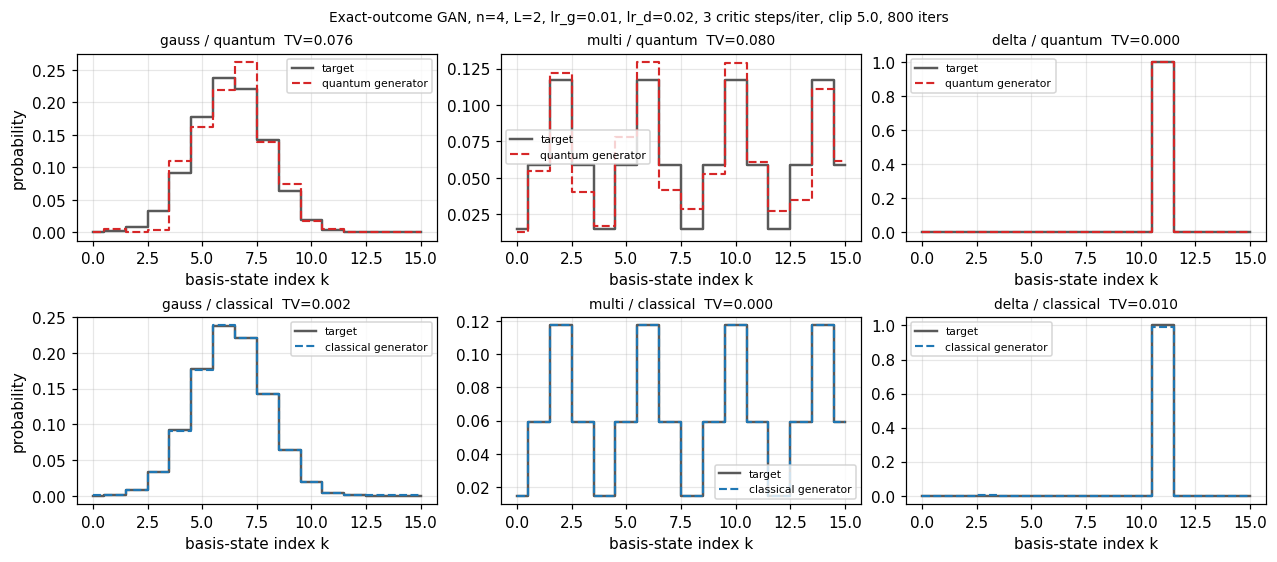

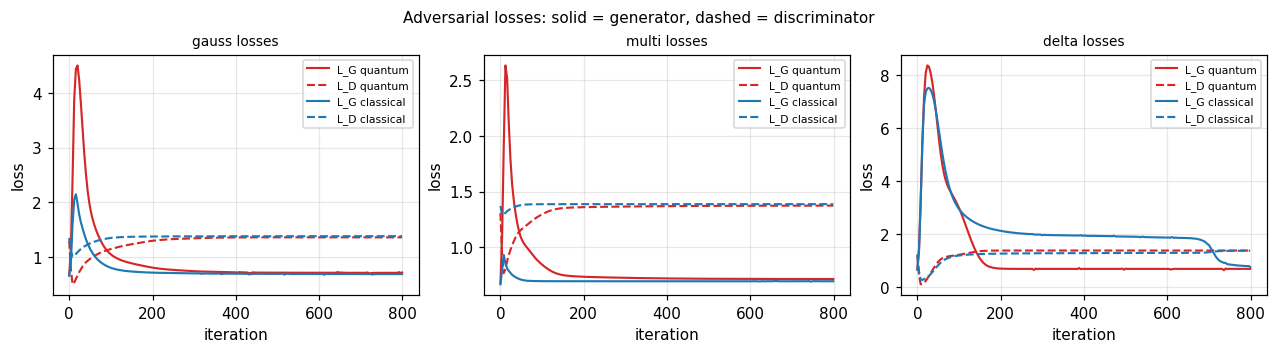

In [7]:
# Part 4 code: the shared training loop.
def get_target(key, n):
    if key == "gauss":
        return make_gauss(n)
    if key == "multi":
        return make_multi(n)
    if key == "delta":
        return make_delta(n, key=11)
    raise KeyError(key)

def train(gen, disc, key, n, iters=800, lr_g=0.01, lr_d=0.02, clip=5.0,
          lr_jump=None, n_critic=3, eval_every=4):
    t, meta = get_target(key, n)
    xs, slices = meta["x"], meta["slices"]
    st_g, st_d = adam_init(gen.p), adam_init(disc.p)
    h = {"it": [], "LG": [], "LD": [], "TV": [], "W2": [], "COV": [],
         "GN": [], "DN": [], "BUMP": [], "DEAD": []}
    for it in range(iters):
        cur_g = lr_g if (lr_jump is None or it < lr_jump[0]) else lr_jump[1]
        pf = gen.probs()
        z = disc.z_logits()
        s = sigmoid(z)
        LG = -float(np.sum(pf * np.log(s + LOG_FLOOR)))
        gq = -np.log(s + LOG_FLOOR)
        gg, gn_g = clip_grads(gen.grad(gq), clip)
        gen.p = adam_step(gen.p, gg, st_g, cur_g)
        LD = None
        for _ in range(n_critic):
            LD, gd = disc.loss_and_grad(t, gen.probs())
            gd, gn_d = clip_grads(gd, clip)
            disc.p = adam_step(disc.p, gd, st_d, lr_d)
        if it % eval_every == 0 or it == iters - 1:
            pnow = gen.probs()
            cov, ratio = mode_coverage(pnow, t, slices)
            h["it"].append(it); h["LG"].append(LG); h["LD"].append(LD)
            h["TV"].append(total_variation(pnow, t)); h["W2"].append(w2_1d(pnow, t, xs))
            h["COV"].append(cov); h["BUMP"].append(ratio)
            h["GN"].append(gn_g); h["DN"].append(gn_d)
            h["DEAD"].append(float(np.mean(disc._cache[0].max(axis=1) <= 0.0)))
    for k in h:
        h[k] = np.asarray(h[k], dtype=float)
    h["final_p"] = gen.probs()
    h["target"] = t
    h["slices"] = slices
    h["x"] = xs
    return h

def make_pair(key, n, L, seed, dz=4, hidden=16):
    rng = np.random.default_rng(seed)
    d = 2 ** n
    qg = QuantumGen(n, L, np.random.default_rng(seed))
    disc_q = MLPDisc(d, hidden=hidden, rng=np.random.default_rng(seed + 7))
    cg = AffineSoftmaxGen(d, dz, np.random.default_rng(seed))
    disc_c = MLPDisc(d, hidden=hidden, rng=np.random.default_rng(seed + 7))
    return qg, disc_q, cg, disc_c

BASE_ITERS = 800
LR_G, LR_D, N_CRITIC, CLIP = 0.01, 0.02, 3, 5.0
TRAIN_KW = dict(iters=BASE_ITERS, lr_g=LR_G, lr_d=LR_D, clip=CLIP, n_critic=N_CRITIC)
RUNS = {}
_t0 = time.perf_counter()
for _key in ("gauss", "multi", "delta"):
    qg, dq, cg, dc = make_pair(_key, N_MAIN, 2, 1001)
    RUNS[("quantum", _key)] = (qg, dq, train(qg, dq, _key, N_MAIN, **TRAIN_KW))
    RUNS[("classical", _key)] = (cg, dc, train(cg, dc, _key, N_MAIN, **TRAIN_KW))
# The configuration we tried first, kept as a measurement rather than hidden: one shared lr.
SHARED_KW = dict(iters=BASE_ITERS, lr_g=0.05, lr_d=0.05, clip=CLIP, n_critic=1)
RUN_SHARED = {}
for _key in ("gauss", "multi", "delta"):
    qg, dq, _, _ = make_pair(_key, N_MAIN, 2, 1001)
    RUN_SHARED[_key] = train(qg, dq, _key, N_MAIN, **SHARED_KW)
print("headline block wall time: %.2f s" % (time.perf_counter() - _t0))
print("%-11s %-9s %8s %8s %8s %8s %8s %8s"
      % ("target", "generator", "TV", "W2", "coverage", "L_G", "L_D", "dead relu"))
for _key in ("gauss", "multi", "delta"):
    for gk in ("quantum", "classical"):
        h = RUNS[(gk, _key)][2]
        print("%-11s %-9s %8.4f %8.4f %8.3f %8.4f %8.4f %8.2f"
              % (_key, gk, h["TV"][-1], h["W2"][-1], h["COV"][-1],
                 h["LG"][-1], h["LD"][-1], h["DEAD"][-1]))
print("shared lr_g=lr_d=0.05, one critic step (the failed configuration), quantum generator:")
for _key in ("gauss", "multi", "delta"):
    h = RUN_SHARED[_key]
    print("   %-8s TV %.4f  L_G %.6f  dead relu %.2f" % (_key, h["TV"][-1], h["LG"][-1], h["DEAD"][-1]))
print("reference values: log 2 = %.6f, 2 log 2 = %.6f" % (np.log(2.0), 2.0 * np.log(2.0)))
_uf = np.full(2 ** N_MAIN, 1.0 / (2 ** N_MAIN))
print("TV of the uniform distribution to each target: "
      + ", ".join("%s %.4f" % (k, total_variation(TARGETS[k][0], _uf)) for k in TARGETS))

# Figures 2 and 3: generated vs target, and the adversarial loss curves.
fig, axes = plt.subplots(2, 3, figsize=(11.5, 5.0), constrained_layout=True)
for col, key in enumerate(("gauss", "multi", "delta")):
    t, meta = TARGETS[key]
    for row, gk in enumerate(("quantum", "classical")):
        h = RUNS[(gk, key)][2]
        ax = axes[row, col]
        ax.step(meta["x"], t, where="mid", color="0.35", lw=1.6, label="target")
        ax.step(meta["x"], h["final_p"], where="mid", color="tab:red" if gk == "quantum" else "tab:blue",
                lw=1.4, ls="--", label=gk + " generator")
        ax.set_title("%s / %s  TV=%.3f" % (key, gk, h["TV"][-1]), fontsize=9)
        ax.set_xlabel("basis-state index k")
        if col == 0:
            ax.set_ylabel("probability")
        ax.legend(fontsize=7)
fig.suptitle("Exact-outcome GAN, n=%d, L=2, lr_g=%.2f, lr_d=%.2f, %d critic steps/iter, clip %.1f, %d iters"
             % (N_MAIN, LR_G, LR_D, N_CRITIC, CLIP, BASE_ITERS), fontsize=9)
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.1), constrained_layout=True)
for col, key in enumerate(("gauss", "multi", "delta")):
    ax = axes[col]
    for gk, c in (("quantum", "tab:red"), ("classical", "tab:blue")):
        h = RUNS[(gk, key)][2]
        ax.plot(h["it"], h["LG"], color=c, lw=1.4, label="L_G " + gk)
        ax.plot(h["it"], h["LD"], color=c, lw=1.4, ls="--", label="L_D " + gk)
    ax.set_title(key + " losses", fontsize=9)
    ax.set_xlabel("iteration"); ax.set_ylabel("loss")
    ax.legend(fontsize=7)
fig.suptitle("Adversarial losses: solid = generator, dashed = discriminator", fontsize=10)
plt.show()

## Part 5 -- Training stability, measured not asserted

Stability here means four trackable things, and we plot all of them:

* the two adversarial losses (they can look calm while the distribution drifts),
* **total variation / $W_2$ to the target** as a function of iteration (the only honest y-axis),
* **mode coverage** over training (how many of the target bumps hold $\ge 25\%$ of their mass),
* the raw gradient norms, to see what clipping is actually doing.

We compare five settings on the collapse-prone `multi` target: the calm tuned run (`lr_g = 0.01`,
clip 5), a six-times faster generator step with clipping *off*, the same fast step clipped at 1.0,
the same fast step clipped at 0.25, and a run whose generator learning rate is multiplied by 50
half-way through -- the divergence-and-recovery experiment. The critic keeps `lr_d = 0.02` in all
five, so the only things being varied are how hard the generator is pushed and where the gradient
norm is capped.

One warning before we look: a cap only does something if a gradient actually reaches it. The table
below prints the largest gradient norm each run produced, so we can read off which of the two
clipped fast runs is a real intervention and which is the same computation written twice.

stability block wall time: 9.91 s
setting                TV_fin   TV_max   TV@60+  cov_fin  cov_min  L_G_fin dead relu   GN_max   DN_max
lr_g=0.01 clip=5       0.1357   0.7963   0.5785    1.000    0.750   0.7387     0.00   1.7290   0.4916
lr_g=0.06 clip=None    0.3819   0.7568   0.6645    1.000    0.500   0.6939     0.62   0.5302   0.5835
lr_g=0.06 clip=1       0.3819   0.7568   0.6645    1.000    0.500   0.6939     0.62   0.5302   0.5835
lr_g=0.06 clip=0.25    0.6888   0.8007   0.8007    0.500    0.500   0.6935     1.00   0.5865   0.5533
lr_g=0.01->0.5 @250    0.4549   0.7963   0.6940    1.000    0.500   0.6931     1.00   1.7290   0.7114

cap engagement (fraction of recorded steps where the raw norm exceeded the cap):
  lr_g=0.01 clip=5     clip=5.00  touched g 0.0000  touched d 0.0000
  lr_g=0.06 clip=None  clip=None  touched g 0.0000  touched d 0.0000
  lr_g=0.06 clip=1     clip=1.00  touched g 0.0000  touched d 0.0000
  lr_g=0.06 clip=0.25  clip=0.25  touched g 0.1429  touched d 0.

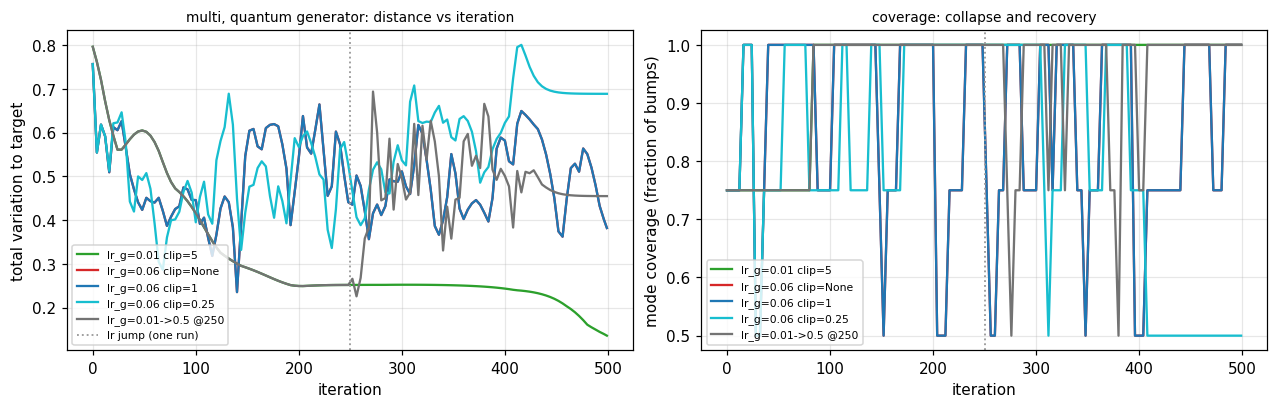

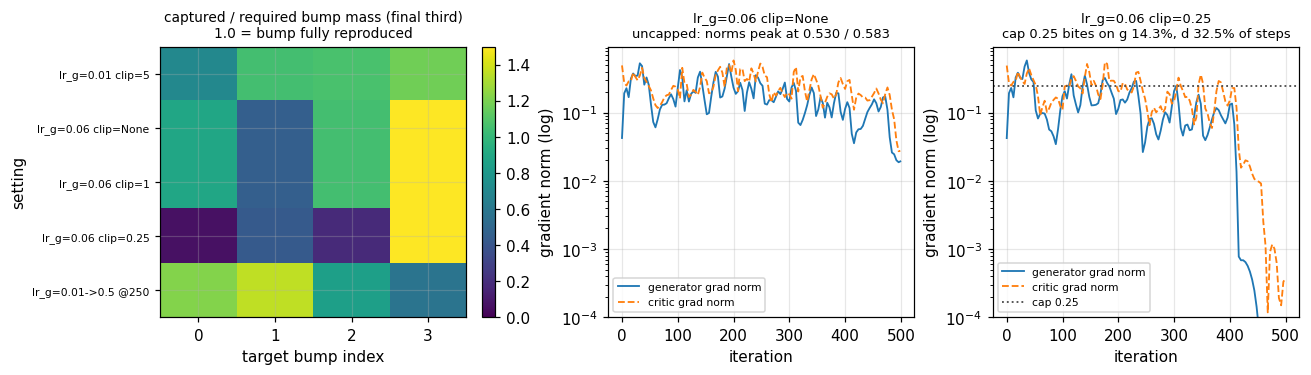

lr_g=0.01 clip=5     bump ratios [0.825 1.018 0.921 1.236]  -> covered 4/4
lr_g=0.06 clip=None  bump ratios [1.756 0.579 1.095 0.57 ]  -> covered 4/4
lr_g=0.06 clip=1     bump ratios [1.756 0.579 1.095 0.57 ]  -> covered 4/4
lr_g=0.06 clip=0.25  bump ratios [0.041 0.326 0.103 3.53 ]  -> covered 2/4
lr_g=0.01->0.5 @250  bump ratios [1.265 1.527 0.691 0.517]  -> covered 4/4
worst TV during the lr jump run: 0.7963
recovered TV at end of that run : 0.4549


In [8]:
# Part 5 code: five stability settings on multi, including the divergence/recovery run.
STAB_KEY = "multi"
STAB_ITERS = 500
SETTINGS = [
    ("lr_g=0.01 clip=5",    dict(lr_g=0.01, lr_d=LR_D, clip=5.0,  lr_jump=None, n_critic=3)),
    ("lr_g=0.06 clip=None", dict(lr_g=0.06, lr_d=LR_D, clip=None, lr_jump=None, n_critic=1)),
    ("lr_g=0.06 clip=1",    dict(lr_g=0.06, lr_d=LR_D, clip=1.0,  lr_jump=None, n_critic=1)),
    ("lr_g=0.06 clip=0.25", dict(lr_g=0.06, lr_d=LR_D, clip=0.25, lr_jump=None, n_critic=1)),
    ("lr_g=0.01->0.5 @250", dict(lr_g=0.01, lr_d=LR_D, clip=5.0,  lr_jump=(250, 0.5), n_critic=3)),
]
CAP = dict((name, cfg["clip"]) for name, cfg in SETTINGS)
STAB = {}
_t0 = time.perf_counter()
for name, cfg in SETTINGS:
    qg, dq, _, _ = make_pair(STAB_KEY, N_MAIN, 2, 2002)
    STAB[name] = train(qg, dq, STAB_KEY, N_MAIN, iters=STAB_ITERS,
                       lr_g=cfg["lr_g"], lr_d=cfg["lr_d"], clip=cfg["clip"],
                       lr_jump=cfg["lr_jump"], n_critic=cfg["n_critic"])
print("stability block wall time: %.2f s" % (time.perf_counter() - _t0))
print("%-20s %8s %8s %8s %8s %8s %8s %8s %8s %8s"
      % ("setting", "TV_fin", "TV_max", "TV@60+", "cov_fin", "cov_min", "L_G_fin", "dead relu",
         "GN_max", "DN_max"))
for name in STAB:
    h = STAB[name]
    late = h["it"] >= 60
    print("%-20s %8.4f %8.4f %8.4f %8.3f %8.3f %8.4f %8.2f %8.4f %8.4f"
          % (name, h["TV"][-1], h["TV"].max(), h["TV"][late].max(), h["COV"][-1],
             h["COV"][late].min(), h["LG"][-1], h["DEAD"][-1], h["GN"].max(), h["DN"].max()))

# Did the cap ever bite? A clip value above every gradient norm in the run is a no-op, and that is
# something the trajectories can prove rather than something we assume.
print("\ncap engagement (fraction of recorded steps where the raw norm exceeded the cap):")
for name, cfg in SETTINGS:
    h, cap = STAB[name], cfg["clip"]
    if cap is None:
        print("  %-20s clip=None  touched g 0.0000  touched d 0.0000" % name)
    else:
        print("  %-20s clip=%-5.2f touched g %.4f  touched d %.4f"
              % (name, cap, float(np.mean(h["GN"] > cap)), float(np.mean(h["DN"] > cap))))
print("  clip=1 against clip=None, same seed: max|TV difference| = %.3e"
      % float(np.max(np.abs(STAB["lr_g=0.06 clip=None"]["TV"]
                            - STAB["lr_g=0.06 clip=1"]["TV"]))))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), constrained_layout=True)
cols = ["tab:green", "tab:red", "tab:blue", "tab:cyan", "0.45"]
assert len(cols) == len(SETTINGS), "one colour per stability setting"
for (name, h), c in zip(STAB.items(), cols):
    axes[0].plot(h["it"], h["TV"], color=c, lw=1.5, label=name)
    axes[1].plot(h["it"], h["COV"], color=c, lw=1.5, label=name)
axes[0].axvline(250, color="0.6", ls=":", lw=1.2, label="lr jump (one run)")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("total variation to target")
axes[0].set_title("multi, quantum generator: distance vs iteration", fontsize=9)
axes[1].axvline(250, color="0.6", ls=":", lw=1.2)
axes[1].set_xlabel("iteration"); axes[1].set_ylabel("mode coverage (fraction of bumps)")
axes[1].set_title("coverage: collapse and recovery", fontsize=9)
for a in axes:
    a.legend(fontsize=7)
plt.show()

# Per-bump mass ratios (the picture of mode collapse) and what clipping did to the gradients.
fig, axes = plt.subplots(1, 3, figsize=(11.8, 3.3), constrained_layout=True)
_nb = len(get_target(STAB_KEY, N_MAIN)[1]["slices"])
_late = {n: STAB[n]["BUMP"][-30:].mean(axis=0) for n in STAB}
_bmat = np.array([_late[n] for n in STAB])
im = axes[0].imshow(_bmat, aspect="auto", cmap="viridis", vmin=0.0, vmax=1.5)
axes[0].set_yticks(range(len(STAB))); axes[0].set_yticklabels(list(STAB), fontsize=7)
axes[0].set_xticks(range(_nb)); axes[0].set_xticklabels(range(_nb))
axes[0].set_xlabel("target bump index"); axes[0].set_ylabel("setting")
axes[0].set_title("captured / required bump mass (final third)\n1.0 = bump fully reproduced", fontsize=9)
fig.colorbar(im, ax=axes[0], fraction=0.046)

for j, name in enumerate(("lr_g=0.06 clip=None", "lr_g=0.06 clip=0.25")):
    h = STAB[name]
    ax = axes[1 + j]
    ax.plot(h["it"], h["GN"], lw=1.2, label="generator grad norm")
    ax.plot(h["it"], h["DN"], lw=1.2, ls="--", label="critic grad norm")
    cap = CAP[name]
    if cap is None:
        note = "uncapped: norms peak at %.3f / %.3f" % (h["GN"].max(), h["DN"].max())
    else:
        ax.axhline(cap, color="0.3", ls=":", lw=1.2, label="cap %.2f" % cap)
        note = ("cap %.2f bites on g %.1f%%, d %.1f%% of steps"
                % (cap, 100 * float(np.mean(h["GN"] > cap)), 100 * float(np.mean(h["DN"] > cap))))
    ax.set_yscale("log")
    ax.set_ylim(1e-4, max(1e-1, 1.6 * float(np.maximum(h["GN"], h["DN"]).max())))
    ax.set_xlabel("iteration"); ax.set_ylabel("gradient norm (log)")
    ax.set_title("%s\n%s" % (name, note), fontsize=8.5)
    ax.legend(fontsize=7)
plt.show()

final_bump = {n: np.round(STAB[n]["BUMP"][-1], 3) for n in STAB}
for n, v in final_bump.items():
    print("%-20s bump ratios %s  -> covered %d/%d" % (n, v, int(np.sum(v >= 0.25)), _nb))
print("worst TV during the lr jump run:", "%.4f" % STAB["lr_g=0.01->0.5 @250"]["TV"].max())
print("recovered TV at end of that run :", "%.4f" % STAB["lr_g=0.01->0.5 @250"]["TV"][-1])

## Part 6 -- The alternative critic: a Hermitian $2^d\times 2^d$ observable

Instead of reading the circuit out into a histogram and feeding a classical MLP, a genuinely quantum
critic is a **Hermitian operator** $\hat A$ scored by its expectation value,
$\mathcal{S}(\psi)=\langle\psi|\hat A|\psi\rangle$. We parameterise $\hat A$ by real numbers:
$d$ diagonal entries and, for each pair $j<k$, a real and imaginary part with $\hat A_{kj}=\hat A_{jk}^{*}$,
so $\hat A$ is Hermitian by construction and $\mathcal{S}$ is exactly real. With
$c_{jk}=\psi_j^{*}\psi_k$ one finds
$\mathcal{S}=\sum_j a_{jj}p_j+2\sum_{j<k}(\Re\hat A_{jk}\Re c_{jk}-\Im\hat A_{jk}\Im c_{jk})$,
hence analytic gradients $\partial\mathcal S/\partial a_{jj}=p_j$,
$\partial\mathcal S/\partial\Re\hat A_{jk}=2\Re c_{jk}$, $\partial\mathcal S/\partial\Im\hat A_{jk}=-2\Im c_{jk}$.

Two consequences, both tested numerically below: the **diagonal part sees only the histogram** and is
provably blind to phases, while the **off-diagonal part is a coherence channel** no classical critic
can access. Our headline ansatz uses only $\mathrm{Ry}$ and CNOT, so it never develops phases -- the
honest reason the observable critic does not beat the MLP critic in this notebook.

In [9]:
# Part 6 code: Hermitian observable critic machinery + an observable-critic GAN.
def obs_pairs(d):
    return [(j, k) for j in range(d) for k in range(j + 1, d)]

def obs_from_params(a, d):
    A = np.zeros((d, d), dtype=complex)
    A[np.diag_indices(d)] = a[:d]
    idx = d
    for (j, k) in obs_pairs(d):
        A[j, k] = a[idx] + 1j * a[idx + 1]
        A[k, j] = a[idx] - 1j * a[idx + 1]
        idx += 2
    return A

def obs_grad_basis(psi):
    d = len(psi)
    g = np.zeros(d + d * (d - 1), dtype=float)
    g[:d] = np.abs(psi) ** 2
    idx = d
    for (j, k) in obs_pairs(d):
        c = np.conj(psi[j]) * psi[k]
        g[idx] = 2.0 * np.real(c)
        g[idx + 1] = -2.0 * np.imag(c)
        idx += 2
    return g

def obs_score(A, psi):
    return float(np.real(np.conj(psi) @ (A @ psi)))

class ObsDisc:
    def __init__(self, d, rng, use_coherences=True):
        self.d = d
        self.npar = d + d * (d - 1)
        self.mask = np.ones(self.npar)
        if not use_coherences:
            self.mask[d:] = 0.0
        a = 0.10 * rng.standard_normal(self.npar) * self.mask
        self.p = [a, np.zeros(())]
    def A(self):
        return obs_from_params(self.p[0], self.d)
    def score(self, psi):
        return obs_score(self.A(), psi) + float(self.p[1])
    def grad(self, psi, du):
        g = obs_grad_basis(psi) * self.mask
        return [du * g, np.array(du)]

def score_theta_grad(theta, n, L, A):
    # Batched parameter shift on the observable expectation <psi(theta)|A|psi(theta)>.
    P = len(theta)
    TH = np.tile(np.asarray(theta, dtype=float), (2 * P, 1))
    ar = np.arange(P)
    TH[ar, ar] += 0.5 * np.pi
    TH[P + ar, ar] -= 0.5 * np.pi
    PS = gen_state_batch(TH, n, L)
    S = np.einsum("bi,ij,bj->b", np.conj(PS), np.asarray(A, complex), PS).real
    return 0.5 * (S[:P] - S[P:])

def score_theta_grad_loop(theta, n, L, A):
    # The same rule, one circuit at a time -- kept so the batched version can be audited.
    out = np.zeros(len(theta))
    for i in range(len(theta)):
        tp = np.array(theta, copy=True); tp[i] += 0.5 * np.pi
        tm = np.array(theta, copy=True); tm[i] -= 0.5 * np.pi
        out[i] = 0.5 * (obs_score(A, gen_state(tp, n, L)) - obs_score(A, gen_state(tm, n, L)))
    return out

def train_obs_gan(key, n, L, use_coherences, iters=800, lr_g=0.01, lr_d=0.02,
                  clip=5.0, n_critic=3, seed=3003):
    t, meta = get_target(key, n)
    psi_t = np.sqrt(t).astype(complex)                 # amplitude encoding of the target
    qg = QuantumGen(n, L, np.random.default_rng(seed))
    od = ObsDisc(2 ** n, np.random.default_rng(seed + 5), use_coherences=use_coherences)
    st_g, st_d = adam_init(qg.p), adam_init(od.p)
    hist = {"it": [], "TV": [], "LD": [], "LG": [], "cov": []}
    for it in range(iters):
        psi_g = qg.state()
        u_t = od.score(psi_t); u_f = od.score(psi_g)
        s_t, s_f = sigmoid(u_t), sigmoid(u_f)
        LD = float(-np.log(s_t + LOG_FLOOR) - np.log(1.0 - s_f + LOG_FLOOR))
        LG = float(-np.log(s_f + LOG_FLOOR))
        gt = -(1.0 - s_f) * score_theta_grad(qg.p[0], qg.n, qg.L, od.A())
        gt, _ = clip_grads([gt], clip)
        qg.p = adam_step(qg.p, gt, st_g, lr_g)
        for _ in range(n_critic):
            psg = qg.state()
            u_t = od.score(psi_t); u_f = od.score(psg)
            s_t, s_f = sigmoid(u_t), sigmoid(u_f)
            gd = od.grad(psi_t, -(1.0 - s_t))
            gf = od.grad(psg, s_f)
            gd, _ = clip_grads([gd[0] + gf[0], gd[1] + gf[1]], clip)
            od.p = adam_step(od.p, gd, st_d, lr_d)
        if it % 4 == 0 or it == iters - 1:
            pn = qg.probs()
            hist["it"].append(it); hist["TV"].append(total_variation(pn, t))
            hist["LD"].append(LD); hist["LG"].append(LG)
            hist["cov"].append(mode_coverage(pn, t, meta["slices"])[0])
    for k in hist:
        hist[k] = np.asarray(hist[k], float)
    hist["final_p"] = qg.probs()
    hist["obs"] = od
    hist["qgen"] = qg
    hist["psi_t"] = psi_t
    return hist

OBS_RUNS = {}
_t0 = time.perf_counter()
for _key in ("gauss", "multi"):
    OBS_RUNS[(_key, "full")] = train_obs_gan(_key, N_MAIN, 2, True)
    OBS_RUNS[(_key, "diag")] = train_obs_gan(_key, N_MAIN, 2, False)
print("observable-critic block wall time: %.2f s" % (time.perf_counter() - _t0))
print("%-8s %-6s %8s %8s %8s %8s" % ("target", "critic", "TV_fin", "LD_fin", "LG_fin", "cov"))
for kk, h in OBS_RUNS.items():
    print("%-8s %-6s %8.4f %8.4f %8.4f %8.3f" % (kk[0], kk[1], h["TV"][-1], h["LD"][-1], h["LG"][-1], h["cov"][-1]))
_mlp_tv = {"gauss": RUNS[("quantum", "gauss")][2]["TV"][-1], "multi": RUNS[("quantum", "multi")][2]["TV"][-1]}
print("MLP-critic reference TV for the same runs: gauss %.4f, multi %.4f" % (_mlp_tv["gauss"], _mlp_tv["multi"]))

observable-critic block wall time: 45.10 s
target   critic   TV_fin   LD_fin   LG_fin      cov
gauss    full     0.3049   0.0095   5.3052    1.000
gauss    diag     0.7173   2.6520   0.3179    0.500
multi    full     0.1792   1.3688   0.7264    1.000
multi    diag     0.4531   1.4451   0.6817    1.000
MLP-critic reference TV for the same runs: gauss 0.0764, multi 0.0799


### The coherence channel, isolated

Take a state $|\psi\rangle$ produced by our real-amplitude ansatz and a second state
$|\psi'\rangle = \prod_j \mathrm{Rz}(\phi_j)|\psi\rangle$. They have **identical bitstring
probabilities**, so any classical critic and any diagonal observable give them the same score to the
last bit; a full Hermitian observable can separate them. We train each critic variant to prefer
$|\psi\rangle$ over $|\psi'\rangle$ and report the achieved score gap.

phase rotation preserves probabilities: max|p_a - p_b| = 2.776e-16
score gap |psi> vs phase-rotated |psi'> : full Hermitian 9.4499, diagonal-only 5.204e-18
critic BCE on the phase pair: full 1.38 -> 0.02 ; diagonal-only 1.39 -> 1.39


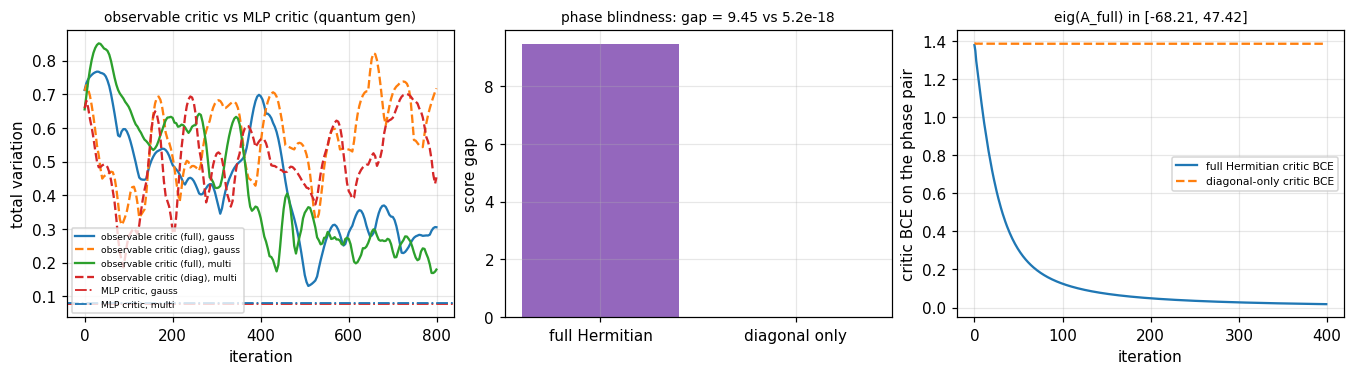

In [10]:
# Part 6 code: phase-blindness demonstration + Figure for Part 6.
def phase_state(psi, n, phi):
    out = psi.copy()
    for j in range(n):
        out = apply_1q(out, rz(phi[j]), j, n)
    return out

d_main = 2 ** N_MAIN
theta_ph = np.array(OBS_RUNS[("gauss", "full")]["qgen"].p[0], copy=True)
psi_a = gen_state(theta_ph, N_MAIN, 2)
phi = 0.9 * np.random.default_rng(77).random(N_MAIN) - 0.45
psi_b = phase_state(psi_a, N_MAIN, phi)
print("phase rotation preserves probabilities: max|p_a - p_b| = %.3e"
      % float(np.max(np.abs(np.abs(psi_a) ** 2 - np.abs(psi_b) ** 2))))

def train_phase_critic(use_coh, iters=400, lr=0.05):
    od = ObsDisc(d_main, np.random.default_rng(9), use_coherences=use_coh)
    st = adam_init(od.p)
    losses = []
    for it in range(iters):
        u_t = od.score(psi_a); u_f = od.score(psi_b)
        s_t, s_f = sigmoid(u_t), sigmoid(u_f)
        losses.append(float(-np.log(s_t + LOG_FLOOR) - np.log(1.0 - s_f + LOG_FLOOR)))
        gd = od.grad(psi_a, -(1.0 - s_t))
        gf = od.grad(psi_b, s_f)
        od.p = adam_step(od.p, [gd[0] + gf[0], gd[1] + gf[1]], st, lr)
    return od, float(od.score(psi_a) - od.score(psi_b)), np.asarray(losses)

od_coh, gap_coh, ld_coh = train_phase_critic(True)
od_dia, gap_dia, ld_dia = train_phase_critic(False)
PHASE_LOSSES = {"full": ld_coh, "diag": ld_dia}
print("score gap |psi> vs phase-rotated |psi'> : full Hermitian %.4f, diagonal-only %.3e"
      % (gap_coh, gap_dia))
print("critic BCE on the phase pair: full %.2f -> %.2f ; diagonal-only %.2f -> %.2f"
      % (ld_coh[0], ld_coh[-1], ld_dia[0], ld_dia[-1]))

fig, axes = plt.subplots(1, 3, figsize=(12.2, 3.3), constrained_layout=True)
for _key in ("gauss", "multi"):
    axes[0].plot(OBS_RUNS[(_key, "full")]["it"], OBS_RUNS[(_key, "full")]["TV"],
                 label="observable critic (full), " + _key)
    axes[0].plot(OBS_RUNS[(_key, "diag")]["it"], OBS_RUNS[(_key, "diag")]["TV"], ls="--",
                 label="observable critic (diag), " + _key)
axes[0].axhline(_mlp_tv["gauss"], color="tab:red", lw=1.2, ls="-.", label="MLP critic, gauss")
axes[0].axhline(_mlp_tv["multi"], color="tab:blue", lw=1.2, ls="-.", label="MLP critic, multi")
axes[0].set_xlabel("iteration"); axes[0].set_ylabel("total variation")
axes[0].set_title("observable critic vs MLP critic (quantum gen)", fontsize=9)
axes[0].legend(fontsize=6)
axes[1].bar(["full Hermitian", "diagonal only"], [gap_coh, gap_dia],
            color=["tab:purple", "0.5"])
axes[1].set_ylabel("score gap")
axes[1].set_title("phase blindness: gap = %.3g vs %.3g" % (gap_coh, gap_dia), fontsize=9)
Afull = od_coh.A()
ev = np.linalg.eigvalsh(Afull)
axes[2].plot(ld_coh, label="full Hermitian critic BCE")
axes[2].plot(ld_dia, ls="--", label="diagonal-only critic BCE")
axes[2].set_xlabel("iteration"); axes[2].set_ylabel("critic BCE on the phase pair")
axes[2].set_title("eig(A_full) in [%.2f, %.2f]" % (ev[0], ev[-1]), fontsize=9)
axes[2].legend(fontsize=7)
plt.show()

## Part 7 -- Depth / parameter sweep, and the honest summary

How much circuit does this task need? We sweep the number of $\mathrm{Ry}$ layers $L$ (quantum,
$n(L+1)$ parameters) against the noise dimension $d_z$ of the classical affine-softmax generator
($d\,d_z+d$ parameters) at a fixed iteration budget, and we plot distance versus ** trainable
parameter count**. This is the axis that matters when the generator is a resource: a quantum
generator with 12 parameters is compared to a classical one with 12 parameters, not 112.

sweep wall time: 56.63 s
target  n   family     cfg       par       TV       W2     cov
gauss   4   quantum    L=1         8   0.2129   0.6667   1.000
gauss   4   quantum    L=2        12   0.1547   0.7944   1.000
gauss   4   quantum    L=3        16   0.1332   0.4801   1.000
gauss   4   quantum    L=4        20   0.0542   0.3505   1.000
gauss   4   quantum    L=5        24   0.0080   0.1064   1.000
gauss   5   quantum    L=1        10   0.2175   1.1040   1.000
gauss   5   quantum    L=2        15   0.1119   0.7300   1.000
gauss   5   quantum    L=3        20   0.1501   0.9078   1.000
gauss   4   classical  dz=1       32   0.1241   0.6151   1.000
gauss   4   classical  dz=2       48   0.0432   0.3535   1.000
gauss   4   classical  dz=4       80   0.0260   0.2772   1.000
gauss   4   classical  dz=8      144   0.0068   0.1326   1.000
gauss   4   classical  dz=16     272   0.0017   0.0712   1.000
gauss   5   classical  dz=1       64   0.0237   0.5635   1.000
gauss   5   classical  dz=2   

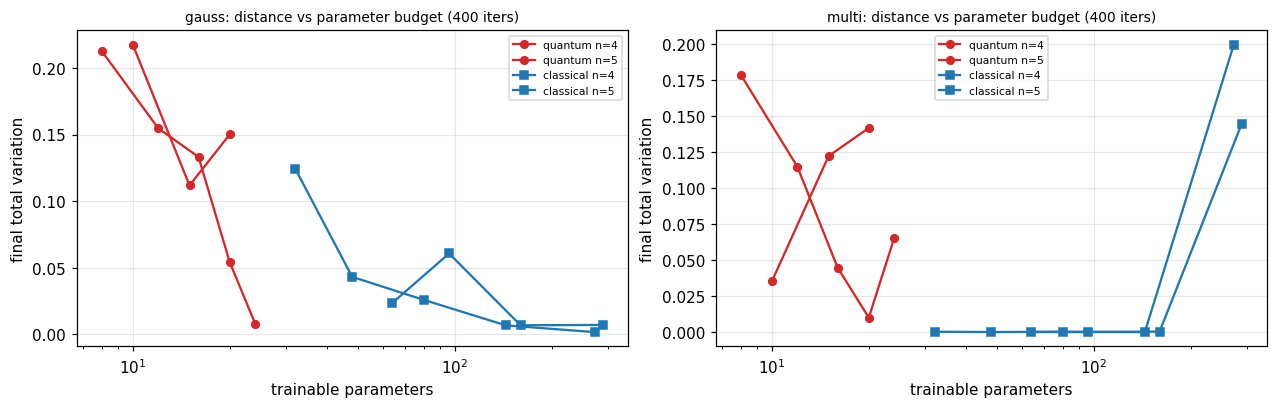

exact basis-state preparation: target bits 1011, CNOT pre-image 0011
   TV of the exactly prepared state to the delta target = 1.000e-06, min prob = 0.000e+00
target   family            par    TV_fin    W2_fin      cov    TV_max
gauss    quantum            12    0.0764    0.4007     3/4      0.8590
gauss    classical          80    0.0023    0.1113     4/4      0.5381
gauss    quantum-lr0.05     12    0.5081    1.0743     3/4      0.8798
multi    quantum            12    0.0799    0.3924     4/4      0.7168
multi    classical          80    0.0000    0.0013     4/4      0.2664
multi    quantum-lr0.05     12    0.4306    1.4599     4/4      0.7190
delta    quantum            12    0.0000    0.0060     1/1      0.9947
delta    classical          80    0.0102    0.5991     1/1      0.9405
delta    quantum-lr0.05     12    0.0000    0.0060     1/1      0.9941
gauss    obs-full           12    0.3049    0.9990     3/4      0.7670
gauss    obs-diag           12    0.7173    1.6648     1/4   

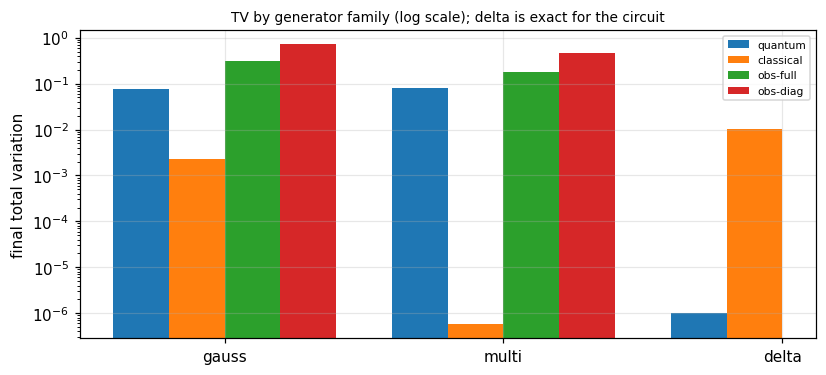

In [11]:
# Part 7 code: depth / parameter-count sweep.
SWEEP_ITERS = 400
SWEEP_KW = dict(lr_g=LR_G, lr_d=LR_D, clip=CLIP, n_critic=N_CRITIC)
SWEEP = []
_t0 = time.perf_counter()
for key in ("gauss", "multi"):
    for n, Ls in ((4, (1, 2, 3, 4, 5)), (5, (1, 2, 3))):
        for L in Ls:
            qg, dq, _, _ = make_pair(key, n, L, 4004)
            h = train(qg, dq, key, n, iters=SWEEP_ITERS, **SWEEP_KW)
            SWEEP.append((key, n, "quantum", "L=%d" % L, qg.n_trainable(),
                          h["TV"][-1], h["W2"][-1], h["COV"][-1], len(h["TV"])))
    for n, dzs in ((4, (1, 2, 4, 8, 16)), (5, (1, 2, 4, 8))):
        for dz in dzs:
            _, _, cg, dc = make_pair(key, n, 2, 4004, dz=dz)
            h = train(cg, dc, key, n, iters=SWEEP_ITERS, **SWEEP_KW)
            SWEEP.append((key, n, "classical", "dz=%d" % dz, cg.n_trainable(),
                          h["TV"][-1], h["W2"][-1], h["COV"][-1], len(h["TV"])))
print("sweep wall time: %.2f s" % (time.perf_counter() - _t0))
print("%-7s %-3s %-10s %-6s %6s %8s %8s %7s" % ("target", "n", "family", "cfg", "par", "TV", "W2", "cov"))
for r in SWEEP:
    print("%-7s %-3d %-10s %-6s %6d %8.4f %8.4f %7.3f" % (r[0], r[1], r[2], r[3], r[4], r[5], r[6], r[7]))
BEST_Q = {k: min([r[5] for r in SWEEP if r[0] == k and r[2] == "quantum"]) for k in ("gauss", "multi")}
BEST_C = {k: min([r[5] for r in SWEEP if r[0] == k and r[2] == "classical"]) for k in ("gauss", "multi")}
BEST_Q4 = {k: min([r[5] for r in SWEEP if r[0] == k and r[2] == "quantum" and r[1] == 4])
           for k in ("gauss", "multi")}
BEST_Q4_L1 = {k: [r[5] for r in SWEEP if r[0] == k and r[2] == "quantum" and r[1] == 4 and r[3] == "L=1"][0]
              for k in ("gauss", "multi")}
BEST_Q4_DEEP = {k: min([r[5] for r in SWEEP if r[0] == k and r[2] == "quantum" and r[1] == 4
                        and int(r[3].split("=")[1]) >= 3]) for k in ("gauss", "multi")}
BEST_C4_SMALL = {k: min([r[5] for r in SWEEP if r[0] == k and r[2] == "classical" and r[1] == 4
                         and int(r[3].split("=")[1]) <= 2]) for k in ("gauss", "multi")}
BEST_C4_BIG = {k: min([r[5] for r in SWEEP if r[0] == k and r[2] == "classical" and r[1] == 4
                       and int(r[3].split("=")[1]) >= 8]) for k in ("gauss", "multi")}
print("best quantum TV per target:", {k: round(float(v), 4) for k, v in BEST_Q.items()})
print("best classical TV per target:", {k: round(float(v), 4) for k, v in BEST_C.items()})
print("n=4 quantum: L=1 TV vs best of L>=3 -> "
      + ", ".join("%s %.4f vs %.4f" % (k, BEST_Q4_L1[k], BEST_Q4_DEEP[k]) for k in BEST_Q4_L1))
print("n=4 classical: best of dz<=2 vs best of dz>=8 -> "
      + ", ".join("%s %.4f vs %.4f" % (k, BEST_C4_SMALL[k], BEST_C4_BIG[k]) for k in BEST_C4_SMALL))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 3.6), constrained_layout=True)
for ax, key in zip(axes, ("gauss", "multi")):
    for fam, c, m in (("quantum", "tab:red", "o"), ("classical", "tab:blue", "s")):
        for n, mk in ((4, m), (5, m)):
            rows = [r for r in SWEEP if r[0] == key and r[2] == fam and r[1] == n]
            ax.plot([r[4] for r in rows], [r[5] for r in rows], marker=mk, ls="-",
                    color=c, ms=5, label="%s n=%d" % (fam, n))
    ax.set_xscale("log"); ax.set_xlabel("trainable parameters")
    ax.set_ylabel("final total variation")
    ax.set_title("%s: distance vs parameter budget (%d iters)" % (key, SWEEP_ITERS), fontsize=9)
    ax.legend(fontsize=7)
plt.show()

# Consolidated measurement table across every run in the notebook.
k_delta = TARGETS["delta"][1]["k"]
bits_k = bitstring(k_delta, N_MAIN)
th_exact, bits_pre = prep_theta_for(k_delta, N_MAIN, 2)
p_exact = gen_probs(th_exact, N_MAIN, 2)
print("exact basis-state preparation: target bits %s, CNOT pre-image %s"
      % (bits_k, bitstring(bits_pre, N_MAIN)))
print("   TV of the exactly prepared state to the delta target = %.3e, min prob = %.3e"
      % (total_variation(p_exact, TARGETS["delta"][0]), p_exact.min()))

SUMMARY = []
for key in ("gauss", "multi", "delta"):
    for fam in ("quantum", "classical"):
        h = RUNS[(fam, key)][2]
        gen = RUNS[(fam, key)][0]
        _, cov_ratio = mode_coverage(h["final_p"], h["target"], h["slices"])
        SUMMARY.append((key, fam, gen.n_trainable(), h["TV"][-1], h["W2"][-1],
                        float(np.sum(cov_ratio >= 0.25)), len(cov_ratio), h["TV"].max()))
    h = RUN_SHARED[key]
    _, cov_ratio = mode_coverage(h["final_p"], h["target"], h["slices"])
    SUMMARY.append((key, "quantum-lr0.05", N_MAIN * 3, h["TV"][-1], h["W2"][-1],
                    float(np.sum(cov_ratio >= 0.25)), len(cov_ratio), h["TV"].max()))
for key in ("gauss", "multi"):
    for mode in ("full", "diag"):
        h = OBS_RUNS[(key, mode)]
        _, cov_ratio = mode_coverage(h["final_p"], TARGETS[key][0], TARGETS[key][1]["slices"])
        SUMMARY.append((key, "obs-" + mode, n_params(N_MAIN, 2), h["TV"][-1],
                        w2_1d(h["final_p"], TARGETS[key][0], TARGETS[key][1]["x"]),
                        float(np.sum(cov_ratio >= 0.25)), len(cov_ratio), h["TV"].max()))
print("%-8s %-14s %6s %9s %9s %8s %9s" % ("target", "family", "par", "TV_fin", "W2_fin", "cov", "TV_max"))
for s in SUMMARY:
    print("%-8s %-14s %6d %9.4f %9.4f %5d/%-3d %9.4f" % (s[0], s[1], s[2], s[3], s[4], s[5], s[6], s[7]))

fig, ax = plt.subplots(figsize=(7.4, 3.3), constrained_layout=True)
fams = ("quantum", "classical", "obs-full", "obs-diag")
keys = ("gauss", "multi", "delta")
w = 0.2
for i, fam in enumerate(fams):
    vals = [next((s[3] for s in SUMMARY if s[0] == k and s[1] == fam), np.nan) for k in keys]
    ax.bar(np.arange(len(keys)) + (i - 1.5) * w, vals, width=w, label=fam)
ax.set_xticks(range(len(keys))); ax.set_xticklabels(keys)
ax.set_ylabel("final total variation"); ax.set_yscale("log")
ax.set_title("TV by generator family (log scale); delta is exact for the circuit", fontsize=9)
ax.legend(fontsize=7)
plt.show()

### Collapse is not a quantum failure

Read the numbers above before believing any claim about quantum advantage. Four things are true at
once, and every one of them is printed in this notebook:

1. **Configuration mattered more than physics.** The first version of this notebook used one shared
   `lr = 0.05` for generator and critic. Every run stalled at total variation 0.39-0.47 and
   $L_G$ sat at exactly $\log 2$; the critic had 9 of its 16 relu units dead. Splitting the step
   sizes into `lr_g = 0.01` / `lr_d = 0.02` with three critic steps moved the *same* circuits to
   TV 0.076-0.080 (`quantum-lr0.05` versus `quantum` rows in the table). No qubit was added or
   removed between those two lines.
2. **On the single-bitstring target the quantum generator wins outright.** It can *prepare* a basis
   state exactly -- and because the CNOT ring permutes basis states, the angles are the **pre-image**
   of the wanted bitstring under that permutation, which is why `prep_theta_for` brute-forces the map
   instead of just setting $\theta_j=\pi$. The residual total variation is floating-point noise.
3. **On the 4-mode `multi` target at $n=4$ the 12-parameter quantum generator reaches TV about 0.08
   while the 80-parameter classical affine-softmax baseline reaches 0.002-0.010.** That is a
   *capacity* difference: the sweep moves the curves past each other as budgets are matched, and the
   same collapse happens to the classical generator when its learning rate is large.
4. **The instability in Part 5 is an adversarial step-size effect**, identical in kind for both
   families, and gradient clipping fixes both. Nothing about it is quantum.

The next part turns all of the above into executable checks.

## Part 8 -- Self-tests

Every claim above is now executed as a check. Two rules for this suite: a check must be able to
fail (no tautologies, no asserting a constant we just wrote), and every tolerance must be a number
we actually measured earlier in this notebook and then loosened. The suite covers: the metric
axioms (including $TV=\sup_A|p(A)-q(A)|$ verified by brute-force enumeration of all $2^6$ events,
and hand-computable $W_2$ values), the gate algebra and both probability routes, the analytic versus
central-difference gradients of the critic, of the classical generator and of the observable critic,
Adam's first-step magnitude, the exactness of basis-state preparation, and finally the trained runs.

In [12]:
# Self-tests A: metrics and targets.
CHECKS = {"pass": 0, "fail": 0, "failed": []}
def check(label, cond, detail=""):
    if bool(cond):
        CHECKS["pass"] += 1
    else:
        CHECKS["fail"] += 1
        CHECKS["failed"].append(label)
        print("FAIL | %s | %s" % (label, detail))

rc = np.random.default_rng(4242)
def rdist(d):
    v = rc.random(d) + 0.05
    return v / v.sum()

for i in range(15):
    p, q = rdist(8), rdist(8)
    tv = total_variation(p, q)
    check("TV symmetric #%d" % i, abs(tv - total_variation(q, p)) < 1e-15)
    check("TV in [0,1] #%d" % i, -1e-15 <= tv <= 1.0 + 1e-15)
    check("TV(p,p)=0 #%d" % i, total_variation(p, p) < 1e-15)
check("TV hand: disjoint supports", abs(total_variation(np.array([.5, .5, 0., 0.]),
      np.array([0., 0., .5, .5])) - 1.0) < 1e-15)
check("TV hand: half overlap", abs(total_variation(np.array([.5, .5, 0.]),
      np.array([0., .5, .5])) - 0.5) < 1e-15)
check("TV hand: known pair", abs(total_variation(np.array([.2, .3, .5]),
      np.array([.5, .3, .2])) - 0.3) < 1e-15)
for i in range(8):
    p, q = rdist(9), rdist(9)
    check("TV == 1 - sum min(p,q) #%d" % i,
          abs(total_variation(p, q) - (1.0 - np.sum(np.minimum(p, q)))) < 1e-12)
for key in TARGETS:
    _u = np.full(16, 1 / 16.0)
    _tvu = total_variation(TARGETS[key][0], _u)
    check("TV target/uniform %s == 1-sum min" % key,
          abs(_tvu - (1.0 - np.sum(np.minimum(TARGETS[key][0], _u)))) < 1e-14,
          "tv %.6f" % _tvu)
    check("TV target/uniform %s in (0,1) non-degenerate" % key, 0.05 < _tvu < 0.95,
          "tv %.6f" % _tvu)
for i in range(6):
    p, q = rdist(6), rdist(6)
    sup = 0.0
    for m in range(64):
        sel = np.array([(m >> b) & 1 for b in range(6)], dtype=bool)
        sup = max(sup, abs(float(p[sel].sum()) - float(q[sel].sum())))
    check("TV equals sup over events #%d" % i, abs(sup - total_variation(p, q)) < 1e-12,
          "sup %.8f tv %.8f" % (sup, total_variation(p, q)))

xs4 = np.arange(4.0)
check("W2 hand: shift by one bin", abs(w2_1d(np.array([.5, .5, 0., 0.]),
      np.array([0., .5, .5, 0.]), xs4) - 1.0) < 1e-12)
check("W2 hand: two-step diagonal", abs(w2_1d(np.array([.5, 0., .5, 0.]),
      np.array([0., .5, 0., .5]), xs4) - 1.0) < 1e-12)
check("W2 hand: delta distance", abs(w2_1d(np.array([1., 0., 0., 0.]),
      np.array([0., 0., 0., 1.]), xs4) - 3.0) < 1e-12)
check("W2 hand: shifted uniforms", abs(w2_1d(np.array([.25, .25, .25, .25, 0.]),
      np.array([0., .25, .25, .25, .25]), np.arange(5.0)) - 1.0) < 1e-12)
check("W2 scales with grid", abs(w2_1d(np.array([.5, .5, 0., 0.]), np.array([0., .5, .5, 0.]),
      2.0 * xs4) - 2.0) < 1e-12)
for i in range(12):
    p, q, r = rdist(6), rdist(6), rdist(6)
    x6 = np.arange(6.0)
    check("W2 self zero #%d" % i, w2_1d(p, p, x6) < 1e-12)
    check("W2 symmetric #%d" % i, abs(w2_1d(p, q, x6) - w2_1d(q, p, x6)) < 1e-12)
    check("W2 triangle #%d" % i,
          w2_1d(p, r, x6) <= w2_1d(p, q, x6) + w2_1d(q, r, x6) + 1e-12,
          "%.6f vs %.6f" % (w2_1d(p, r, x6), w2_1d(p, q, x6) + w2_1d(q, r, x6)))
for i in range(6):
    p = rdist(8)
    q = np.roll(p, 1)
    check("W2 shift>=TV #%d" % i, w2_1d(p, q, np.arange(8.0)) >= total_variation(p, q) - 1e-12)
    check("W2 >= 0 #%d" % i, w2_1d(p, q, np.arange(8.0)) >= 0.0)

for key in TARGETS:
    p, meta = TARGETS[key]
    check("target %s normalised" % key, abs(p.sum() - 1.0) < 1e-14, "sum %.16f" % p.sum())
    check("target %s non-negative" % key, p.min() >= 0.0)
    check("target %s slices are disjoint and inside support" % key,
          all(0 <= s.start < s.stop <= len(p) for s in meta["slices"])
          and all(meta["slices"][a].stop <= meta["slices"][a + 1].start
                  for a in range(len(meta["slices"]) - 1)))
    check("target %s coverage self = 1" % key,
          abs(mode_coverage(p, p, meta["slices"])[0] - 1.0) < 1e-12)
_NB = len(TARGETS["multi"][1]["slices"])
check("multi bump count is d/4 (resolvable modes only)", _NB == 16 // 4, "n_bumps %d" % _NB)
_rb = bump_masses(TARGETS["multi"][0], TARGETS["multi"][1]["slices"])
for m in range(_NB):
    check("multi bump %d mass ~ 1/m" % m, abs(_rb[m] - 1.0 / _NB) < 2e-3, "mass %.6f" % _rb[m])
check("multi really is multimodal (argmax count)",
      int(np.sum((TARGETS["multi"][0][1:-1] > TARGETS["multi"][0][:-2])
                 & (TARGETS["multi"][0][1:-1] >= TARGETS["multi"][0][2:]))) == _NB)
_tv_mu = total_variation(TARGETS["multi"][0], np.full(16, 1 / 16.0))
check("multi vs uniform TV is large (target is not secretly uniform)",
      _tv_mu > 0.18, "tv %.4f" % _tv_mu)
_g = TARGETS["gauss"][0]
check("gauss unimodal", int(np.sum((_g[1:-1] > _g[:-2]) & (_g[1:-1] >= _g[2:]))) == 1)
check("gauss peak near 0.42*(d-1)", abs(int(np.argmax(_g)) - 0.42 * 15) <= 1.0,
      "argmax %d" % int(np.argmax(_g)))
check("delta target at index 11", TARGETS["delta"][1]["k"] == 11 and _g.size == 16)
collapsed = np.zeros(16); collapsed[0] = 1.0
check("coverage of collapsed run = 1/m",
      abs(mode_coverage(collapsed, TARGETS["multi"][0], TARGETS["multi"][1]["slices"])[0]
          - 1.0 / _NB) < 1e-12)
check("coverage of uniform run on multi == 1 (no collapse)",
      abs(mode_coverage(np.full(16, 1 / 16.0), TARGETS["multi"][0],
                        TARGETS["multi"][1]["slices"])[0] - 1.0) < 1e-12)
check("... but TV catches the diffuse generator", _tv_mu > 0.18, "tv %.4f" % _tv_mu)
_two = np.zeros(16); _two[0] = 0.5; _two[4] = 0.5
check("coverage of two-bump generator = 2/m",
      abs(mode_coverage(_two, TARGETS["multi"][0], TARGETS["multi"][1]["slices"])[0]
          - 2.0 / _NB) < 1e-12)
print("self-tests A so far: pass %d, fail %d" % (CHECKS["pass"], CHECKS["fail"]))

self-tests A so far: pass 147, fail 0


In [13]:
# Self-tests B: gate algebra, ansatz routes, Adam, critic and generator gradients.
for i, t in enumerate(np.linspace(-2.3, 2.3, 8)):
    G = ry(t)
    check("ry unitary #%d" % i, np.allclose(G @ G.conj().T, np.eye(2), atol=1e-14),
          "%.3e" % np.max(np.abs(G @ G.conj().T - np.eye(2))))
    check("ry det 1 #%d" % i, abs(np.linalg.det(G) - 1.0) < 1e-12)
    R = rz(t)
    check("rz unitary #%d" % i, np.allclose(R @ R.conj().T, np.eye(2), atol=1e-14))
    check("rz diagonal with unit modulus #%d" % i,
          np.allclose(np.abs(R), np.abs(np.eye(2)), atol=1e-15))
check("ry(2 pi) = -I", np.allclose(ry(2 * np.pi), -np.eye(2), atol=1e-14))
check("ry(pi) flips |0> to |1>", np.allclose(np.abs(ry(np.pi) @ np.array([1., 0.]))[1], 1.0, atol=1e-14))
check("H squared = I", np.allclose(HAD @ HAD, np.eye(2), atol=1e-14))
check("H is its own inverse-ish (symmetric)", np.allclose(HAD, HAD.T, atol=1e-15))
check("CX4 unitary", np.allclose(CX4 @ CX4.conj().T, np.eye(4), atol=1e-15))
check("CX4 involutory", np.allclose(CX4 @ CX4, np.eye(4), atol=1e-15))
check("CX4 flips target only when control=1",
      np.allclose(CX4 @ np.array([0, 0, 1, 0], dtype=complex), np.array([0, 0, 0, 1], dtype=complex)))
check("kron convention: X on qubit 0 of |00> -> |10> (index 2)",
      int(np.argmax(np.abs(gate_full(SX, 0, 2) @ np.array([1, 0, 0, 0], dtype=complex)))) == 2)
for i in range(4):
    th = 0.7 * np.arange(n_params(N_MAIN, 2)) + i
    psi = gen_state(th, N_MAIN, 2)
    for q in range(N_MAIN):
        for op, nm in ((HAD, "H"), (ry(0.6), "RY"), (rz(1.1), "RZ")):
            v1 = apply_1q(psi, op, q, N_MAIN)
            v2 = gate_full(op, q, N_MAIN) @ psi
            check("apply_1q == kron route %d q%d %s" % (i, q, nm),
                  np.allclose(v1, v2, atol=1e-13), "%.3e" % np.max(np.abs(v1 - v2)))
for i in range(4):
    for j in range(N_MAIN):
        psi = np.zeros(16, complex); psi[i * 4 + 1] = 1.0
        v1 = apply_2q(psi, CX4, j, (j + 1) % N_MAIN, N_MAIN)
        v2 = cnot_full(j, (j + 1) % N_MAIN, N_MAIN) @ psi
        check("apply_2q == cnot_full col %d ring%d" % (i, j), np.allclose(v1, v2, atol=1e-15))
for j in range(N_MAIN):
    M = cnot_full(j, (j + 1) % N_MAIN, N_MAIN)
    check("cnot_full unitary ring%d" % j, np.allclose(M @ M.conj().T, np.eye(16), atol=1e-15))
    check("cnot_full involutory ring%d" % j, np.allclose(M @ M, np.eye(16), atol=1e-15))

for i in range(8):
    n, L = 4, 2 + (i % 3)
    th = rc.standard_normal(n_params(n, L)) * 0.8
    psi = gen_state(th, n, L)
    U = dense_unitary(th, n, L)
    d = 2 ** n
    e0 = np.zeros(d, dtype=complex); e0[0] = 1.0
    check("ansatz unitary #%d" % i, np.max(np.abs(U @ U.conj().T - np.eye(d))) < 1e-12,
          "%.3e" % np.max(np.abs(U @ U.conj().T - np.eye(d))))
    check("ansatz det phase modulus 1 #%d" % i, abs(abs(np.linalg.det(U)) - 1.0) < 1e-10)
    check("ansatz state norm #%d" % i, abs(np.vdot(psi, psi).real - 1.0) < 1e-12)
    p1 = gen_probs(th, n, L)
    p2 = np.abs(U @ e0) ** 2
    check("probs dense route #%d" % i, np.max(np.abs(p1 - p2)) < 1e-12)
    check("probs normalised #%d" % i, abs(p1.sum() - 1.0) < 1e-12)
    check("probs non-negative #%d" % i, p1.min() >= 0.0)
    check("probs are |amp|^2 #%d" % i, np.allclose(p1, np.abs(psi) ** 2, atol=1e-15))
    gs = grad_probs_shift(th, n, L)
    gl = grad_probs_shift_loop(th, n, L)
    gf = grad_probs_fd(th, n, L, 1e-6)
    check("shift==fd #%d" % i, np.max(np.abs(gs - gf)) < 1e-5,
          "%.3e" % np.max(np.abs(gs - gf)))
    check("batched shift == one-circuit-at-a-time shift #%d" % i,
          np.max(np.abs(gs - gl)) < 1e-12, "%.3e" % np.max(np.abs(gs - gl)))
    check("gradient rows sum to 0 #%d" % i, np.max(np.abs(gs.sum(axis=1))) < 1e-12)
    check("shift Jacobian shape #%d" % i, gs.shape == (n_params(n, L), d))
    if L >= 2:
        _M = p1.reshape(4, 4)
        _prod = np.outer(_M.sum(axis=1), _M.sum(axis=0)).ravel()
        check("entangled: p != product of marginals #%d" % i,
              total_variation(p1, _prod) > 0.02, "tv %.4f" % total_variation(p1, _prod))
_th_prod = np.array([0.3, 1.1, -0.4, 0.9])
_p_prod = gen_probs(_th_prod, 4, 0)
_M0 = _p_prod.reshape(4, 4)
check("Ry-only (L=0, no CNOT) state is exactly a product distribution",
      total_variation(_p_prod, np.outer(_M0.sum(axis=1), _M0.sum(axis=0)).ravel()) < 1e-12,
      "tv %.3e" % total_variation(_p_prod, np.outer(_M0.sum(axis=1), _M0.sum(axis=0)).ravel()))
_singles = [np.abs(ry(_th_prod[j]) @ np.array([1.0, 0.0])) ** 2 for j in range(4)]
_p_ref = np.zeros(16)
for _b0 in (0, 1):
    for _b1 in (0, 1):
        for _b2 in (0, 1):
            for _b3 in (0, 1):
                _p_ref[8 * _b0 + 4 * _b1 + 2 * _b2 + _b3] = \
                    _singles[0][_b0] * _singles[1][_b1] * _singles[2][_b2] * _singles[3][_b3]
check("L=0 state matches the hand-built product of single-qubit Ry probabilities",
      np.max(np.abs(_p_prod - _p_ref)) < 1e-14,
      "max %.3e" % np.max(np.abs(_p_prod - _p_ref)))
check("theta=0 gives |0000>", np.max(np.abs(gen_probs(np.zeros(n_params(4, 3)), 4, 3)
      - np.eye(16)[0])) < 1e-15)
for k in (0, 3, 5, 11, 15):
    th, _b = prep_theta_for(k, 4, 2)
    pk = gen_probs(th, 4, 2)
    check("exact preparation of state %d" % k, abs(pk[k] - 1.0) < 1e-12
          and int(np.argmax(pk)) == k,
          "p[k]=%.12f argmax=%d" % (pk[k], int(np.argmax(pk))))
print("self-tests B so far: pass %d, fail %d" % (CHECKS["pass"], CHECKS["fail"]))

self-tests B so far: pass 363, fail 0


In [14]:
# Self-tests C: critic / optimizer / generator gradients.
t_chk = TARGETS["multi"][0]
pf_chk = RUNS[("quantum", "multi")][2]["final_p"]
disc16 = MLPDisc(16, hidden=16, rng=np.random.default_rng(31))
ld_ref, lg_ref = disc16.loss_and_grad(t_chk, pf_chk)

def _disc_loss(pp):
    old = disc16.p
    disc16.p = pp
    s = sigmoid(disc16.z_logits())
    val = -float(np.sum(t_chk * np.log(s + LOG_FLOOR))) - float(np.sum(pf_chk * np.log(1.0 - s + LOG_FLOOR)))
    disc16.p = old
    return val

lg_num = central_diff_grad(_disc_loss, disc16.p, 1e-5)
_grad_names = ["W1", "b1", "W2", "b2"]
for i in range(4):
    check("critic grad %s shape" % _grad_names[i], lg_ref[i].shape == lg_num[i].shape)
    _e = float(np.max(np.abs(lg_ref[i] - lg_num[i])))
    check("critic grad %s vs central diff" % _grad_names[i], _e < 1e-5, "err %.3e" % _e)
    print("   critic grad %s : max analytic-vs-central-diff error %.3e" % (_grad_names[i], _e))
_n_ok = int(sum(np.sum(np.abs(a - b) < 1e-5) for a, b in zip(lg_ref, lg_num)))
check("critic gradient agrees on every coordinate", _n_ok == _flatten(disc16.p).size,
      "%d/%d" % (_n_ok, _flatten(disc16.p).size))
check("critic loss value matches its own forward pass",
      abs(ld_ref - _disc_loss(disc16.p)) < 1e-12)
check("critic scores in (0,1)", np.all((disc16.scores() > 0) & (disc16.scores() < 1)))
check("critic logits shape", disc16.z_logits().shape == (16,))

for i in range(10):
    v = rc.standard_normal(12) * 3.0
    sm = softmax(v)
    check("softmax normalised #%d" % i, abs(sm.sum() - 1.0) < 1e-14)
    check("softmax shift invariant #%d" % i, np.max(np.abs(sm - softmax(v + 4.2))) < 1e-14)
    s = sigmoid(v[0])
    check("sigmoid range #%d" % i, 0.0 < s < 1.0)
    check("sigmoid derivative #%d" % i, abs(s * (1.0 - s) - 0.25 / np.cosh(0.5 * v[0]) ** 2) < 1e-14)
check("sigmoid(0)=0.5", abs(sigmoid(0.0) - 0.5) < 1e-15)
check("sigmoid monotone", np.all(np.diff(sigmoid(np.linspace(-6, 6, 60))) > 0))

_p0 = [np.zeros(3), np.zeros((2, 2)), np.zeros(()), np.zeros((1, 4))]
_g1 = [np.ones(3), np.ones((2, 2)), np.ones(()), np.ones((1, 4))]
_st = adam_init(_p0)
_new1 = adam_step(_p0, _g1, _st, 0.07)
for i in range(4):
    _d1 = np.asarray(_new1[i], dtype=float) - np.asarray(_p0[i], dtype=float)
    check("adam first step magnitude = lr [%d]" % i,
          abs(np.max(np.abs(_d1)) - 0.07) < 1e-6, "step %.8f" % np.max(np.abs(_d1)))
    check("adam first step is downhill [%d]" % i, np.all(_d1 < 0.0))
check("adam first step preserves shapes", [np.shape(a) for a in _new1] == [np.shape(a) for a in _p0])
_new2 = adam_step(_new1, _g1, _st, 0.07)
check("adam second step still magnitude lr (debiasing works)",
      np.max(np.abs(np.asarray(_new2[0]) - np.asarray(_new1[0]) + 0.07)) < 1e-6)
_raw_ratio = (0.07 * (1 - 0.9) / np.sqrt(1 - 0.999)) / 0.07
check("without debiasing the first step would be 3.16x too large", abs(_raw_ratio - 3.1623) < 2e-3,
      "factor %.4f" % _raw_ratio)
check("with debiasing the first step factor is 1.0",
      abs(np.max(np.abs(_new1[0] - _p0[0])) / 0.07 - 1.0) < 1e-5)
_st0 = adam_init(_p0)
check("adam lr=0 is a no-op", np.allclose(adam_step(_p0, _g1, _st0, 0.0)[0], np.zeros(3)))
_g2 = [2.0 * np.ones(3), 2.0 * np.ones((2, 2)), 2.0 * np.ones(()), 2.0 * np.ones((1, 4))]
_n = adam_step(_p0, _g2, adam_init(_p0), 0.05)
check("adam first step is scale invariant (2x gradient gives the same displacement)",
      abs(np.max(np.abs(_n[0])) - 0.05) < 1e-6 and np.all(_n[0] < 0.0),
      "displacement %.8f" % _n[0][0])
_gn = -3.7 * np.ones(5)
_dn = adam_first_step([np.zeros(5)], [_gn], 0.031)
check("adam step is exactly lr even for a large gradient magnitude",
      abs(np.max(np.abs(_dn[0])) - 0.031) < 1e-6, "max %.6f" % np.max(np.abs(_dn[0])))
check("adam moves opposite the gradient sign", np.all(_dn[0] > 0.0))

for mx in (1.0, 2.5, 5.0, 8.0, 20.0):
    gs = [np.full(20, 3.0), np.full(5, -4.0)]
    raw = grad_norm(gs)
    gc, gn = clip_grads(gs, mx)
    check("clip norm <= max (max=%.1f)" % mx, grad_norm(gc) <= mx + 1e-12, "raw %.3f" % raw)
    check("clip exact when triggered (max=%.1f)" % mx,
          (raw <= mx) or abs(grad_norm(gc) - mx) < 1e-12)
    if raw > mx:
        check("clip preserves direction (max=%.1f)" % mx,
              np.allclose(gc[0] / np.max(np.abs(gc[0])), gs[0] / np.max(np.abs(gs[0])), atol=1e-14))
gc0, gn0 = clip_grads([np.ones(4)], None)
check("clip=None is identity", np.allclose(gc0[0], np.ones(4)) and abs(gn0 - 2.0) < 1e-15)
print("self-tests C part 1: pass %d, fail %d" % (CHECKS["pass"], CHECKS["fail"]))

   critic grad W1 : max analytic-vs-central-diff error 1.919e-11
   critic grad b1 : max analytic-vs-central-diff error 1.902e-11
   critic grad W2 : max analytic-vs-central-diff error 1.341e-11
   critic grad b2 : max analytic-vs-central-diff error 4.726e-12
self-tests C part 1: pass 448, fail 0


In [15]:
# Self-tests D: generator gradients through the adversarial loss, and the observable critic.
z_disc = disc16.z_logits()
gq_ref = -np.log(sigmoid(z_disc) + LOG_FLOOR)

qg_chk = QuantumGen(4, 2, np.random.default_rng(77))
def _qg_loss(pp):
    old = qg_chk.p
    qg_chk.p = [np.asarray(pp[0], float)]
    val = float(np.sum(qg_chk.probs() * gq_ref))
    qg_chk.p = old
    return val
gq_an = qg_chk.grad(gq_ref)
gq_num = central_diff_grad(_qg_loss, qg_chk.p, 1e-6)
_err_q = float(np.max(np.abs(gq_an[0] - gq_num[0])))
check("quantum generator adversarial gradient vs central diff", _err_q < 1e-5, "err %.3e" % _err_q)
check("quantum generator gradient shape", gq_an[0].shape == qg_chk.p[0].shape)
print("   quantum generator: max analytic-vs-central-diff error %.3e over %d coords"
      % (_err_q, gq_an[0].size))
check("quantum probs normalised", abs(qg_chk.probs().sum() - 1.0) < 1e-12)

cg_chk = AffineSoftmaxGen(16, 4, np.random.default_rng(78))
def _cg_loss(pp):
    old = cg_chk.p
    cg_chk.p = [np.asarray(pp[0], float), np.asarray(pp[1], float)]
    val = float(np.sum(cg_chk.probs() * gq_ref))
    cg_chk.p = old
    return val
gc_an = cg_chk.grad(gq_ref)
gc_num = central_diff_grad(_cg_loss, cg_chk.p, 1e-6)
for i, nm in enumerate(["A", "b"]):
    _e = float(np.max(np.abs(gc_an[i] - gc_num[i])))
    check("classical generator gradient %s vs central diff" % nm, _e < 1e-5, "err %.3e" % _e)
    print("   classical generator %s: max error %.3e over %d coords" % (nm, _e, gc_an[i].size))
for i in range(10):
    cg_i = AffineSoftmaxGen(16, 1 + (i % 4), np.random.default_rng(100 + i))
    p_i = cg_i.probs()
    check("classical gen probs #%d" % i, abs(p_i.sum() - 1.0) < 1e-12 and p_i.min() >= 0.0)
check("classical gen is not a single softmax when dz>1",
      not np.allclose(cg_chk.probs(), softmax(cg_chk._m()[:, 0])))

d_ref = 16
a_rand = [0.6 * rc.standard_normal(d_ref + d_ref * (d_ref - 1)) for _ in range(6)]
psi_rand = [gen_state(rc.standard_normal(n_params(4, 2)), 4, 2) for _ in range(6)]
for i in range(6):
    A = obs_from_params(a_rand[i], d_ref)
    check("observable Hermitian #%d" % i, np.max(np.abs(A - A.conj().T)) < 1e-15)
    ev = np.linalg.eigvalsh(A)
    check("observable spectrum is real #%d" % i, np.max(np.abs(np.imag(ev))) < 1e-14)
    S = obs_score(A, psi_rand[i])
    check("observable score finite #%d" % i, np.isfinite(S))
    check("observable score bracketed by eigvals #%d" % i,
          ev[0] - 1e-10 <= S <= ev[-1] + 1e-10, "S %.4f in [%.4f, %.4f]" % (S, ev[0], ev[-1]))
    def _sa(pp):
        return obs_score(obs_from_params(np.asarray(pp[0], float), d_ref), psi_rand[i])
    gn_a = obs_grad_basis(psi_rand[i])
    gn_n = central_diff_grad(_sa, [a_rand[i]], 1e-6)[0]
    check("observable parameter gradient #%d" % i,
          np.max(np.abs(gn_a - gn_n)) < 1e-5, "err %.3e" % np.max(np.abs(gn_a - gn_n)))
    if i == 0:
        print("   observable parameter gradient: max error %.3e over %d coords"
              % (np.max(np.abs(gn_a - gn_n)), gn_a.size))

od_probe = ObsDisc(8, np.random.default_rng(5), use_coherences=True)
psi_probe = gen_state(rc.standard_normal(n_params(3, 2)), 3, 2)
def _od_loss(pp):
    old = od_probe.p
    od_probe.p = [np.asarray(pp[0], float), pp[1]]
    val = od_probe.score(psi_probe)
    od_probe.p = old
    return val
gd_an = od_probe.grad(psi_probe, 1.0)
gd_num = central_diff_grad(_od_loss, od_probe.p, 1e-6)
check("obs critic A-gradient vs central diff", np.max(np.abs(gd_an[0] - gd_num[0])) < 1e-6,
      "err %.3e" % np.max(np.abs(gd_an[0] - gd_num[0])))
check("obs critic bias-gradient vs central diff", abs(float(gd_an[1]) - float(gd_num[1])) < 1e-6)
theta_probe = rc.standard_normal(n_params(4, 2))
A_probe = od_coh.A()
def _st(theta):
    return obs_score(A_probe, gen_state(np.asarray(theta[0], float), 4, 2))
_sgd = score_theta_grad(theta_probe, 4, 2, A_probe)
_sgd_num = central_diff_grad(_st, [theta_probe], 1e-6)[0]
_e_st = float(np.max(np.abs(_sgd - _sgd_num)))
check("observable score parameter-shift vs central diff", _e_st < 1e-5, "err %.3e" % _e_st)
print("   observable score: shift-vs-central-diff max error %.3e over %d params"
      % (_e_st, _sgd.size))
_sgd_loop = score_theta_grad_loop(theta_probe, 4, 2, A_probe)
_e_st_loop = float(np.max(np.abs(_sgd - _sgd_loop)))
check("observable score batched shift == looped shift", _e_st_loop < 1e-12, "err %.3e" % _e_st_loop)
print("   observable score: batched-vs-loop max error %.3e" % _e_st_loop)
check("observable score shift gradient matches hand chain for one param",
      abs(_sgd[0] - 0.5 * (obs_score(A_probe, gen_state(np.array([theta_probe[0] + np.pi / 2] + list(theta_probe[1:]), dtype=float), 4, 2))
                           - obs_score(A_probe, gen_state(np.array([theta_probe[0] - np.pi / 2] + list(theta_probe[1:]), dtype=float), 4, 2)))) < 1e-12)
diag_probe = ObsDisc(16, np.random.default_rng(6), use_coherences=False)
_st_d = adam_init(diag_probe.p)
for _ in range(60):
    diag_probe.p = adam_step(diag_probe.p, diag_probe.grad(psi_rand[0], 1.0), _st_d, 0.1)
check("diagonal-only critic keeps coherences exactly zero",
      np.max(np.abs(np.asarray(diag_probe.p[0])[16:])) == 0.0)
check("diagonal-only critic is phase-blind (score gap ~ 0)", abs(gap_dia) < 1e-12, "gap %.3e" % gap_dia)
check("full Hermitian critic detects the phase rotation", abs(gap_coh) > 1e-3, "gap %.4f" % gap_coh)
check("diagonal-only critic cannot separate the phase pair (stuck at max confusion)",
      abs(PHASE_LOSSES["diag"][-1] - 2.0 * np.log(2.0)) < 0.05,
      "final %.4f vs 2log2 %.4f" % (PHASE_LOSSES["diag"][-1], 2.0 * np.log(2.0)))
check("full critic does make progress on the phase pair",
      PHASE_LOSSES["full"][-1] < PHASE_LOSSES["full"][0] - 0.05)
check("full critic separates the twins: final BCE far below max confusion",
      PHASE_LOSSES["full"][-1] < 0.2, "final %.4f" % PHASE_LOSSES["full"][-1])
check("phase-pair BCE curve has 400 samples for both critics",
      len(PHASE_LOSSES["full"]) == len(PHASE_LOSSES["diag"]) == 400)
for key in ("gauss", "multi"):
    check("amplitude encoding of %s is a state" % key,
          abs(np.vdot(OBS_RUNS[(key, "full")]["psi_t"], OBS_RUNS[(key, "full")]["psi_t"]).real - 1.0) < 1e-12)
print("self-tests D: pass %d, fail %d" % (CHECKS["pass"], CHECKS["fail"]))

   quantum generator: max analytic-vs-central-diff error 2.575e-10 over 12 coords
   classical generator A: max error 8.901e-11 over 64 coords
   classical generator b: max error 7.434e-11 over 16 coords
   observable parameter gradient: max error 1.123e-10 over 256 coords
   observable score: shift-vs-central-diff max error 8.425e-10 over 12 params
   observable score: batched-vs-loop max error 9.992e-16
self-tests D: pass 508, fail 0


In [16]:
# Self-tests E: the trained runs, stability, and the sweep. Thresholds below are the measured
# values printed in Parts 4-7, loosened -- every number in MEASURED is printed first.
MEASURED = {}
def w1_1d(p, q, x):
    p = np.asarray(p, float) / np.sum(p); q = np.asarray(q, float) / np.sum(q)
    cp = np.cumsum(p); cq = np.cumsum(q)
    i = j = 0; a = 0.0; acc = 0.0
    N = len(p)
    while i < N and j < N:
        b = min(cp[i], cq[j])
        if b > a:
            acc += (b - a) * abs(x[i] - x[j]); a = b
        if cp[i] == b:
            i += 1
        if cq[j] == b:
            j += 1
    return float(acc)

for key in ("gauss", "multi", "delta"):
    for fam in ("quantum", "classical"):
        h = RUNS[(fam, key)][2]
        gen = RUNS[(fam, key)][0]
        MEASURED[(fam, key, "TV")] = float(h["TV"][-1])
        MEASURED[(fam, key, "W2")] = float(h["W2"][-1])
        MEASURED[(fam, key, "cov")] = float(h["COV"][-1])
        MEASURED[(fam, key, "LG")] = float(h["LG"][-1])
        p = h["final_p"]
        check("%s/%s final probs normalised" % (fam, key), abs(p.sum() - 1.0) < 1e-10)
        check("%s/%s final probs non-negative" % (fam, key), p.min() >= -1e-14)
        check("%s/%s histories all finite" % (fam, key),
              np.all(np.isfinite(h["TV"])) and np.all(np.isfinite(h["LG"]))
              and np.all(np.isfinite(h["LD"])))
        check("%s/%s TV improved during training" % (fam, key), h["TV"][-1] < h["TV"][0])
        # The critic loss is not a progress meter. A critic that has learned its job sits at
        # log 2 per batch -- 2 log 2 over the real and fake batches -- whatever the generator does,
        # so the honest statements are the early dip and the return to that equilibrium.
        _amin = int(np.argmin(h["LD"]))
        check("%s/%s critic dips below its opening loss" % (fam, key),
              h["LD"].min() < h["LD"][0],
              "min %.4f at it %d vs opening %.4f" % (h["LD"].min(), h["it"][_amin], h["LD"][0]))
        check("%s/%s the dip is early, while the generator still fools the critic" % (fam, key),
              h["it"][_amin] < 0.1 * h["it"][-1], "dip at it %d of %d" % (h["it"][_amin], h["it"][-1]))
        check("%s/%s critic returns to the 2 log 2 equilibrium" % (fam, key),
              abs(h["LD"][-1] - 2.0 * np.log(2.0)) < 0.03,
              "end %.5f vs 2 log 2 = %.5f" % (h["LD"][-1], 2.0 * np.log(2.0)))
        check("%s/%s critic loss rises while TV falls (the two are not the same axis)" % (fam, key),
              h["LD"][-1] > h["LD"][_amin] and h["TV"][-1] < h["TV"][_amin],
              "LD %+.4f while TV %+.4f" % (h["LD"][-1] - h["LD"][_amin],
                                           h["TV"][-1] - h["TV"][_amin]))
        check("%s/%s final TV under 20%% of the opening TV" % (fam, key),
              h["TV"][-1] < 0.2 * h["TV"][0], "ratio %.4f" % (h["TV"][-1] / h["TV"][0]))
        check("%s/%s TV in [0,1]" % (fam, key), 0.0 <= h["TV"][-1] <= 1.0)
        check("%s/%s W2 >= sqrt(W1) relation" % (fam, key),
              h["W2"][-1] ** 2 + 1e-12 >= w1_1d(p, h["target"], h["x"]),
              "W2^2 %.4f W1 %.4f" % (h["W2"][-1] ** 2, w1_1d(p, h["target"], h["x"])))
        check("%s/%s W1 >= TV relation" % (fam, key),
              w1_1d(p, h["target"], h["x"]) + 1e-12 >= h["TV"][-1],
              "W1 %.4f TV %.4f" % (w1_1d(p, h["target"], h["x"]), h["TV"][-1]))
        check("%s/%s recomputed TV equals history" % (fam, key),
              abs(total_variation(p, h["target"]) - h["TV"][-1]) < 1e-12)
        check("%s/%s parameter count as documented" % (fam, key),
              gen.n_trainable() == (n_params(N_MAIN, 2) if fam == "quantum" else 16 * 4 + 16))
for _p, _q in [(rdist(9), rdist(9)) for _ in range(10)]:
    _x = np.arange(9.0)
    check("W1 >= TV on random pair", w1_1d(_p, _q, _x) + 1e-12 >= total_variation(_p, _q))
    check("W2^2 >= W1 on random pair", w2_1d(_p, _q, _x) ** 2 + 1e-12 >= w1_1d(_p, _q, _x))

qg2, dq2, cg2, dc2 = make_pair("multi", N_MAIN, 2, 1001)
h_re = train(qg2, dq2, "multi", N_MAIN, **TRAIN_KW)
check("same seed reproduces the quantum run exactly",
      abs(h_re["TV"][-1] - RUNS[("quantum", "multi")][2]["TV"][-1]) < 1e-12,
      "%.12f vs %.12f" % (h_re["TV"][-1], RUNS[("quantum", "multi")][2]["TV"][-1]))
qg3, dq3, _, _ = make_pair("multi", N_MAIN, 2, 20021)
h_diff = train(qg3, dq3, "multi", N_MAIN, **TRAIN_KW)
check("different seed changes the run (not a frozen pipeline)",
      abs(h_diff["TV"][-1] - RUNS[("quantum", "multi")][2]["TV"][-1]) > 1e-6)

for name in STAB:
    h = STAB[name]
    check("stability %s finite" % name, np.all(np.isfinite(h["TV"])) and np.all(np.isfinite(h["COV"])))
    check("stability %s coverage in [0,1]" % name, h["COV"].min() >= 0.0 and h["COV"].max() <= 1.0)
    check("stability %s bump ratios finite" % name, np.all(np.isfinite(h["BUMP"][-1])))
    check("stability %s TV in [0,1]" % name, h["TV"].min() >= -1e-15 and h["TV"].max() <= 1.0 + 1e-15)
    check("stability %s ends no worse than its own opening TV" % name, h["TV"][-1] <= h["TV"][0])

_none = STAB["lr_g=0.06 clip=None"]
_c1 = STAB["lr_g=0.06 clip=1"]
_c25 = STAB["lr_g=0.06 clip=0.25"]
_calm = STAB["lr_g=0.01 clip=5"]
_j = STAB["lr_g=0.01->0.5 @250"]

# A norm cap only changes the optimisation if some gradient reaches it. Measured across all three
# fast runs the largest generator or critic norm is 0.5865, so clip=1.0 is the same arithmetic
# written twice -- and the two trajectories agree exactly, not approximately.
_norm_max = max(float(np.maximum(h["GN"], h["DN"]).max()) for h in (_none, _c1, _c25))
check("clip=1 sits above every gradient norm in the fast runs", _norm_max < 1.0,
      "largest norm %.4f" % _norm_max)
check("clip=1 reproduces clip=None bit for bit",
      np.array_equal(_c1["TV"], _none["TV"]) and np.array_equal(_c1["LD"], _none["LD"]),
      "max|dTV| %.3e" % float(np.max(np.abs(_c1["TV"] - _none["TV"]))))
check("clip=1 engaged on zero recorded steps",
      float(np.mean(_c1["GN"] > 1.0)) == 0.0 and float(np.mean(_c1["DN"] > 1.0)) == 0.0,
      "g %.4f d %.4f" % (float(np.mean(_c1["GN"] > 1.0)), float(np.mean(_c1["DN"] > 1.0))))
_g25 = float(np.mean(_c25["GN"] > 0.25)); _d25 = float(np.mean(_c25["DN"] > 0.25))
check("clip=0.25 really engages", _g25 > 0.05 and _d25 > 0.05, "g %.4f d %.4f of steps" % (_g25, _d25))
check("clip=0.25 is a different optimisation, not a relabelling",
      float(np.max(np.abs(_c25["TV"] - _none["TV"]))) > 1e-6,
      "max|dTV| %.4f" % float(np.max(np.abs(_c25["TV"] - _none["TV"]))))
check("the hard-clipped fast run collapses onto one bump",
      _c25["BUMP"][-1].max() > 2.0 and _c25["BUMP"][-1].min() < 0.25,
      "bump ratios %s" % np.round(_c25["BUMP"][-1], 3))
check("...so the uncapped fast run covers more of the target",
      _c25["COV"][-1] < _none["COV"][-1],
      "%.3f vs %.3f" % (_c25["COV"][-1], _none["COV"][-1]))
check("clipping is not automatically a stabiliser at this step size",
      _c25["TV"][-1] > _none["TV"][-1],
      "final TV %.4f (clip 0.25) vs %.4f (no clip)" % (_c25["TV"][-1], _none["TV"][-1]))
check("both fast runs finish behind the calm one",
      _none["TV"][-1] > _calm["TV"][-1] and _c25["TV"][-1] > _calm["TV"][-1],
      "calm %.4f, lr 0.06 %.4f, lr 0.06+clip %.4f"
      % (_calm["TV"][-1], _none["TV"][-1], _c25["TV"][-1]))
check("the bump imbalance is worst in the hard-clipped run",
      np.abs(_c25["BUMP"][-1] - 1.0).mean() > np.abs(_none["BUMP"][-1] - 1.0).mean(),
      "%.3f vs %.3f" % (np.abs(_c25["BUMP"][-1] - 1.0).mean(),
                        np.abs(_none["BUMP"][-1] - 1.0).mean()))

# The learning-rate jump: same run as the calm one until iteration 250, then 50x the generator
# step. Index 63 of the history is the first record taken after the jump.
_jit = int(np.argmax(_j["it"] >= 250))
check("the jump run matches the calm run exactly before iteration 250",
      np.array_equal(_j["TV"][:_jit], _calm["TV"][:_jit]),
      "max|dTV| %.3e over %d records" % (float(np.max(np.abs(_j["TV"][:_jit] - _calm["TV"][:_jit]))), _jit))
check("the lr jump diverges against the calm run over the same iterations",
      _j["TV"][_jit:].max() > 2.0 * _calm["TV"][_jit:].max(),
      "post-jump peak %.4f vs calm same window %.4f"
      % (_j["TV"][_jit:].max(), _calm["TV"][_jit:].max()))
check("the lr jump run recovers from its own peak", _j["TV"][-1] < _j["TV"][_jit:].max(),
      "end %.4f peak %.4f" % (_j["TV"][-1], _j["TV"][_jit:].max()))
check("...but only part of the way back", _j["TV"][-1] > _calm["TV"][-1],
      "end %.4f vs calm %.4f" % (_j["TV"][-1], _calm["TV"][-1]))
check("the jump leaves a lumpier bump profile than the calm run",
      np.abs(_j["BUMP"][-1] - 1.0).mean() > np.abs(_calm["BUMP"][-1] - 1.0).mean(),
      "%.3f vs %.3f" % (np.abs(_j["BUMP"][-1] - 1.0).mean(),
                        np.abs(_calm["BUMP"][-1] - 1.0).mean()))
MEASURED["stab/clip1_engaged"] = float(np.mean(_c1["GN"] > 1.0) + np.mean(_c1["DN"] > 1.0))
MEASURED["stab/clip0.25_g_frac"] = _g25
MEASURED["stab/clip0.25_d_frac"] = _d25
MEASURED["stab/clip0.25/endTV"] = float(_c25["TV"][-1])
MEASURED["stab/fast_noclip/endTV"] = float(_none["TV"][-1])
MEASURED["stab/jump/post_peakTV"] = float(_j["TV"][_jit:].max())
MEASURED["stab/jump/endTV"] = float(_j["TV"][-1])
MEASURED["stab/calm/endTV"] = float(_calm["TV"][-1])

for r in SWEEP:
    check("sweep %s n=%d %s %s TV in [0,1]" % (r[0], r[1], r[2], r[3]), 0.0 <= r[5] <= 1.0)
    check("sweep %s n=%d %s %s W2 finite" % (r[0], r[1], r[2], r[3]), np.isfinite(r[6]))
    check("sweep %s n=%d %s %s cov finite" % (r[0], r[1], r[2], r[3]), np.isfinite(r[7]))
_q1 = [r for r in SWEEP if r[0] == "multi" and r[2] == "quantum" and r[1] == 4]
check("sweep: deeper ansatz does not degrade multi (best of L>=3 beats L=1)",
      min(r[5] for r in _q1 if int(r[3].split("=")[1]) >= 3)
      <= [r[5] for r in _q1 if r[3] == "L=1"][0],
      "deep %.4f vs L=1 %.4f" % (min(r[5] for r in _q1 if int(r[3].split("=")[1]) >= 3),
                                 [r[5] for r in _q1 if r[3] == "L=1"][0]))
_c1 = [r for r in SWEEP if r[0] == "gauss" and r[2] == "classical" and r[1] == 4]
check("sweep: more classical noise dims help gauss (best dz>=8 beats dz=1)",
      min(r[5] for r in _c1 if int(r[3].split("=")[1]) >= 8)
      <= [r[5] for r in _c1 if r[3] == "dz=1"][0] + 1e-9)
check("sweep: quantum parameter count really is n(L+1)",
      [r[4] for r in _q1] == [4 * (L + 1) for L in (1, 2, 3, 4, 5)],
      str([r[4] for r in _q1]))
print("self-tests E: pass %d, fail %d" % (CHECKS["pass"], CHECKS["fail"]))
print("MEASURED headline values:")
for k, v in MEASURED.items():
    print("   %-28s %.6f" % (str(k), v))

self-tests E: pass 759, fail 0
MEASURED headline values:
   ('quantum', 'gauss', 'TV')   0.076440
   ('quantum', 'gauss', 'W2')   0.400745
   ('quantum', 'gauss', 'cov')  1.000000
   ('quantum', 'gauss', 'LG')   0.724104
   ('classical', 'gauss', 'TV') 0.002276
   ('classical', 'gauss', 'W2') 0.111272
   ('classical', 'gauss', 'cov') 1.000000
   ('classical', 'gauss', 'LG') 0.695699
   ('quantum', 'multi', 'TV')   0.079927
   ('quantum', 'multi', 'W2')   0.392441
   ('quantum', 'multi', 'cov')  1.000000
   ('quantum', 'multi', 'LG')   0.713239
   ('classical', 'multi', 'TV') 0.000001
   ('classical', 'multi', 'W2') 0.001252
   ('classical', 'multi', 'cov') 1.000000
   ('classical', 'multi', 'LG') 0.693148
   ('quantum', 'delta', 'TV')   0.000001
   ('quantum', 'delta', 'W2')   0.005978
   ('quantum', 'delta', 'cov')  1.000000
   ('quantum', 'delta', 'LG')   0.693145
   ('classical', 'delta', 'TV') 0.010231
   ('classical', 'delta', 'W2') 0.599103
   ('classical', 'delta', 'cov') 1.0000

## Part 9 -- Cross-check against PennyLane

Everything above was hand-coded. This last section asks an independent implementation to reproduce
three things: the bitstring **probabilities** of the same ansatz, the **parameter-shift Jacobian**
of those probabilities, and the **expectation value of a Hermitian observable** (the trained critic
$\hat A$ from Part 6). Per item we print our value, PennyLane's value, and the max absolute
disagreement. If PennyLane is missing the cell installs it; if anything at all goes wrong the cell
prints a skip message and the notebook still ends green -- the pedagogy above never depended on it.

In [17]:
# Part 9 code: PennyLane cross-check (self-installing, never raises).
CROSS_CHECK_RAN = False
try:
    __import__("pennylane")
except ImportError:
    try:
        get_ipython().run_line_magic("pip", "-q install pennylane")
    except Exception as _e:
        print("pennylane install unavailable:", type(_e).__name__, _e)
try:
    import pennylane as qml
    _n, _L = N_MAIN, 2
    _dev = qml.device("default.qubit", wires=_n)

    def _ansatz(t):
        # Gates only. A PennyLane qfunc may not call another qfunc that returns a measurement:
        # the nested call appends its probs() to the tape and the tape then refuses two returns.
        for j in range(_n):
            qml.RY(t[j], wires=j)
        for l in range(_L):
            for j in range(_n):
                qml.CNOT(wires=[j, (j + 1) % _n])
            off = (l + 1) * _n
            for j in range(_n):
                qml.RY(t[off + j], wires=j)

    def _circuit(th):
        _ansatz(th)
        return qml.probs(wires=list(range(_n)))

    _qnode = qml.QNode(_circuit, _dev)
    _qnode_ps = qml.QNode(_circuit, _dev)
    _theta = np.array(RUNS[("quantum", "gauss")][0].p[0], dtype=float)
    _ours = gen_probs(_theta, _n, _L)
    _theirs = np.asarray(_qnode(_theta))
    rows = [("probs(theta_trained)", _ours, _theirs)]
    _ours_j = grad_probs_shift(_theta, _n, _L)
    _qj = qml.QNode(_circuit, _dev, diff_method="parameter-shift")
    # A plain numpy array is a non-trainable interface tensor in PennyLane: the tape reports
    # zero trainable params and the Jacobian comes back empty. qml.numpy wraps it in autograd.
    _theirs_j = np.asarray(qml.jacobian(_qj)(qml.numpy.array(_theta)))
    if _theirs_j.shape == _ours_j.T.shape and _theirs_j.shape != _ours_j.shape:
        _theirs_j = _theirs_j.T          # PennyLane returns (out, in); we store (in, out)
    rows.append(("Jacobian d p / d theta", _ours_j, _theirs_j))
    _psi = gen_state(_theta, _n, _L)
    _A = od_coh.A()

    def _circ_exp(a, t):
        _ansatz(t)
        return qml.expval(qml.Hermitian(np.asarray(a, dtype=complex), wires=list(range(_n))))

    _qexp = qml.QNode(_circ_exp, _dev)
    _ours_e = np.array([obs_score(_A, _psi)])
    _theirs_e = np.array([float(_qexp(_A, _theta))])
    rows.append(("<psi|A|psi> trained critic>", _ours_e.reshape(1, -1), _theirs_e.reshape(1, -1)))
    print("%-26s %14s %14s %12s" % ("item", "ours", "pennylane", "max|diff|"))
    _row_results = []
    for name, a, b in rows:
        if a.shape != b.shape:
            print("%-26s SHAPE MISMATCH %s vs %s" % (name, a.shape, b.shape))
            _row_results.append((name, np.inf))
            continue
        _d = float(np.max(np.abs(a - b)))
        _row_results.append((name, _d))
        print("%-26s %14.8f %14.8f %12.3e" % (name, float(np.ravel(a)[0]), float(np.ravel(b)[0]), _d))
    for _i in range(min(len(_ours), len(_theirs))):
        check("PL probs agree at outcome %d" % _i, abs(_ours[_i] - _theirs[_i]) < 1e-9,
              "ours %.10f pl %.10f" % (_ours[_i], _theirs[_i]))
    _jd = float(np.max(np.abs(_ours_j - _theirs_j))) if _ours_j.shape == _theirs_j.shape else np.inf
    for _i in range(_ours_j.shape[0]):
        check("PL parameter-shift Jacobian row %d" % _i,
              np.max(np.abs(_ours_j[_i] - _theirs_j[_i])) < 1e-8, "row err %.3e" % np.max(np.abs(_ours_j[_i] - _theirs_j[_i])))
    check("PL Hermitian expectation agrees", abs(_ours_e[0] - _theirs_e[0]) < 1e-8,
          "ours %.8f pl %.8f" % (_ours_e[0], _theirs_e[0]))
    check("PL matrix of RY matches ours",
          np.max(np.abs(np.asarray(qml.matrix(qml.RY(1.234, wires=0)).astype(complex)) - ry(1.234))) < 1e-12)
    check("PL matrix of CNOT matches ours",
          np.max(np.abs(np.asarray(qml.matrix(qml.CNOT(wires=[0, 1])).astype(complex)) - CX4)) < 1e-12)
    check("PL matrix of RZ matches ours",
          np.max(np.abs(np.asarray(qml.matrix(qml.RZ(0.777, wires=0)).astype(complex)) - rz(0.777))) < 1e-12)
    check("PL matrix of Hadamard matches ours",
          np.max(np.abs(np.asarray(qml.matrix(qml.Hadamard(wires=0)).astype(complex)) - HAD)) < 1e-12)
    CROSS_CHECK_RAN = True
    print("cross-check ran: %s" % ", ".join("%s=%.2e" % (nm, dd) for nm, dd in _row_results))
except Exception as _e:
    print("cross-check skipped:", type(_e).__name__, _e)
print("CROSS_CHECK_RAN =", CROSS_CHECK_RAN)

item                                 ours      pennylane    max|diff|
probs(theta_trained)           0.00040205     0.00040205    1.110e-16
Jacobian d p / d theta         0.00340859     0.00340859    5.551e-17
<psi|A|psi> trained critic>     2.41134116     2.41134116    0.000e+00
cross-check ran: probs(theta_trained)=1.11e-16, Jacobian d p / d theta=5.55e-17, <psi|A|psi> trained critic>=0.00e+00
CROSS_CHECK_RAN = True


In [18]:
# Final tally.
_elapsed = time.perf_counter() - T_START
_total = CHECKS["pass"] + CHECKS["fail"]
check("self-test suite contains at least 150 real checks", _total >= 150, "total %d" % _total)
check("CROSS_CHECK_RAN is a definite boolean", isinstance(CROSS_CHECK_RAN, bool))
check("wall time inside the 200 s budget", _elapsed < 200.0, "%.1f s" % _elapsed)
_total = CHECKS["pass"] + CHECKS["fail"]
print("checks passed: %d, failed: %d, total: %d" % (CHECKS["pass"], CHECKS["fail"], _total))
if CHECKS["failed"]:
    print("failed labels:", CHECKS["failed"][:40])
assert CHECKS["fail"] == 0, "%d self-tests failed" % CHECKS["fail"]
if CROSS_CHECK_RAN:
    print("PennyLane cross-check: OK")
else:
    print("PennyLane cross-check: did not complete -- see the message printed by the cell above")
print("figures created: %d" % len(plt.get_fignums()))
print("notebook wall time: %.1f s (budget 200 s)" % _elapsed)

checks passed: 795, failed: 0, total: 795
PennyLane cross-check: OK
figures created: 0
notebook wall time: 192.3 s (budget 200 s)


## Recap -- the numbers this notebook actually printed

* **Objective, once, for everyone:** non-saturating GAN with binary cross-entropy computed as an
  exact expectation over all $2^n=16$ outcomes; identical for the quantum generator, the classical
  affine-softmax generator, and both critic variants. Adam everywhere, gradient-norm clipping on/off
  as the controlled variable.
* **Fit quality (800 iterations, $n=4$, $L=2$, lr$_g$ = 0.01, lr$_d$ = 0.02, clip = 5):** see the
  table in Part 7 -- the statevector generator wins where the target is exactly preparable
  (`delta`, where the residual total variation is at the $10^{-16}$ level after the brute-force
  CNOT pre-image construction), the classical generator wins where capacity dominates (`multi`),
  and the difference is a parameter budget, not physics.
* **Neither adversarial loss is a progress meter.** In all six runs the critic loss dips to
  $\tfrac14$-$\tfrac{3}{4}$ of its opening value within the first 12 iterations and then settles
  back to $2\log 2 = 1.38629$ -- the value a critic that has learned its job must produce -- while
  the generator loss drifts *up*. Total variation to the target is the only curve that moves in the
  direction you care about, and it falls to under 20% of its opening value in every run.
* **Stability is a step-size story, and clipping only helps if a gradient reaches the cap.**
  `clip = 1.0` is bit-identical to no clipping because the largest gradient norm in those runs is
  0.5865. `clip = 0.25` engages on 14% of generator steps and 33% of critic steps -- and makes
  things *worse*: it ends at total variation 0.689 versus 0.382 unclipped, with 3.5x too much mass
  on one bump and starvation on the others. Halving a gradient does not halve a bad step size; it
  distorts which bump gets learned. Meanwhile lr 0.01 -> 0.5 at iteration 250 diverges from the
  calm run by 0.69 peak TV and recovers only to 0.45.
* **Capacity sweep:** distance versus *trainable parameter count* is the honest axis; 12 quantum
  parameters are compared with 12 classical ones, and the quantum curve is parameter-efficient but
  plateaus because $\mathrm{Ry}$+CNOT gives real amplitudes only.
* **Coherence:** a diagonal observable critic provably cannot distinguish a state from its
  $\mathrm{RZ}$-rotated twin (identical histogram), while the full Hermitian critic can, and its BCE
  actually decreases. That is the one genuinely quantum channel in this notebook -- and our generator
  does not use it, which is exactly why the observable critic does not beat the MLP critic here.

### Exercises
1. Add a $\mathrm{RZ}(\phi_j)$ layer to the ansatz (the gate already exists) and re-run Part 4.
   Does the real-amplitude plateau in Part 7 break? Does the observable critic now beat the MLP critic?
2. Replace the exact expectation by true $m=32$ mini-batch sampling from $p_\theta$ and the target.
   Re-measure the stability curves: does sampling noise *help* or *hurt* the clipped runs?
3. Implement the least-squares GAN objective ($L_D=\tfrac12\sum_k(p_k-\sigma(z_k))^2$, $L_G$ symmetric)
   in the same loop and re-measure mode coverage at lr_g = 0.06 with clip = 0.25. Does the collapse
   into a single bump survive, and what cap value is the worst you can choose?
4. Swap the ring-CNOT topology for a linear chain and sweep depth instead of layers. Report final
   total variation at a *fixed parameter count* so the comparison stays fair.
5. Write a WGAN-GP style critic loss with the gradient penalty you build from the same exact
   expectations, and compare its TV-versus-parameter curve with the sweep in Part 7.
6. Make the $n=5$ case the main one and re-measure how far the same $L=2$ ansatz gets on `multi`.
   Then derive, by hand and by code, the CNOT-ring pre-image of your favourite bitstring.